### Code to analyse the background quality of coronagraphic observation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from scipy import ndimage
from scipy.optimize import curve_fit
from astropy.stats import sigma_clip
from astropy.io import fits
import glob
#from collections import defaultdict
from scipy import ndimage
import math
import glob, os
import datetime



In [3]:
### Path and list of background I will analyse
### a transformer en fonction 

sigmabkg = False

if sigmabkg == True:
    path = "/home/cperrot/Work/raw/JWST/Target/MAST/"

    files = glob.glob(path+'CAL/P*/obs*/*background*.fits',recursive=True)  # photometric calibrated background
    #files = glob.glob(path+'P*/obs*/*_mirimage_rate.fits',recursive=True) # DN/s background

    savepath = "/home/cperrot/Work/projet/JWST/Target/backgrounds/obs/"

if sigmabkg == False:
    path = "/home/cperrot/Work/projet/JWST/Target/backgrounds/obs/"
    #path = "/home/cperrot/Work/raw/JWST/Target/MAST/"

    #files = glob.glob(path+'P*/output_with_photom/obs*/*background*.fits',recursive=True)  # photometric calibrated background
    files = glob.glob(path+'F*/P0*background*.fits',recursive=True)  # photometric calibrated background
    #files = glob.glob(path+'F*/*_mirimage_rate.fits',recursive=True) # DN/s background


    
textunit = "MJy/sr"
#textunit = "DN/s"





files.sort()
print(str(len(files))+" files.")

'''
bkg_param = defaultdict(list)
index_img = 0
for fi in files:
    img = fits.open(fi)
    name_fi = img[0].header['FILENAME']
    prog_id = img[0].header['PROGRAM']
    obs_nb  = img[0].header['OBSERVTN']
    name_tar= img[0].header['TARGNAME']
    cat_tar = img[0].header['TARGCAT']
    filt    = img[0].header['FILTER']
    bkg_tar = img[0].header['BKGDTARG'] #True   
    if bkg_tar == True:
        index_img += 1
        bkg_param["INDEX"].append(index_img)
        bkg_param["PATH"].append(fi)
        bkg_param["FILENAME"].append(name_fi)
        bkg_param["PROGRAM"].append(prog_id)
        bkg_param["OBSERVTN"].append(obs_nb)
        bkg_param["TARGNAME"].append(name_tar)
        bkg_param["TARGCAT"].append(cat_tar)
        bkg_param["FILTER"].append(filt)
        bkg_param["BKGDTARG"].append(bkg_tar)        
     '''   



index   = []
path_fi = []
name_fi = []
prog_id = []
obs_id  = []
name_tar= []
cat_tar = []
filtre  = []
ngroups = []       
eff_exp = []  
dateobs = []
timeobs = []
index_img = 0
     
ndim = 200
x0 = 120
y0 = 114    
    
for fi in files:
    img = fits.open(fi)
    if img[0].header['BKGDTARG'] == True:
        index.append(index_img)
        path_fi.append(fi)
        name_fi.append(img[0].header['FILENAME'])
        prog_id.append(img[0].header['PROGRAM'])
        obs_id.append(img[0].header['OBSERVTN'])
        name_tar.append(img[0].header['TARGNAME'])
        cat_tar.append(img[0].header['TARGCAT'])
        filtre.append(img[0].header['FILTER'])
        ngroups.append(img[0].header['NGROUPS'])
        eff_exp.append(img[0].header['EFFEXPTM'])
        dateobs.append(datetime.datetime.strptime(img[0].header['DATE-OBS'], '%Y-%m-%d').date())
        timeobs.append(img[0].header['TIME-OBS'])
        index_img += 1
        if sigmabkg == True:
            bkg = fits.open(fi)[1].data
            bkg = bkg[y0-ndim//2:y0+ndim//2,x0-ndim//2:x0+ndim//2]
           # bkg = imp.sigma_clip_jwst(bkg,3)        
            imp.save_fits_h(bkg,savepath+img[0].header['FILTER']+"/"+img[0].header['FILENAME'],img[0].header)

index    = np.array(index)
path_fi  = np.array(path_fi)
name_fi  = np.array(name_fi)
prog_id  = np.array(prog_id)
obs_id   = np.array(obs_id)
name_tar = np.array(name_tar)
cat_tar  = np.array(cat_tar)
filtre   = np.array(filtre)
ngroups  = np.array(ngroups)
eff_exp  = np.array(eff_exp)
dateobs  = np.array(dateobs)
timeobs  = np.array(timeobs)
   

'''
index    = index[dateobs.argsort()]
path_fi  = path_fi[dateobs.argsort()]
name_fi  = name_fi[dateobs.argsort()]
prog_id  = prog_id[dateobs.argsort()]
obs_id   = obs_id[dateobs.argsort()]
name_tar = name_tar[dateobs.argsort()]
cat_tar  = cat_tar[dateobs.argsort()]
filtre   = filtre[dateobs.argsort()]
ngroups  = ngroups[dateobs.argsort()]
eff_exp  = eff_exp[dateobs.argsort()]
timeobs  = timeobs[dateobs.argsort()]
'''

#format = '%Y-%m-%d'
#for j in dateobs:
    # convert from string format to datetime format
    # and get the date
 #   print(datetime.datetime.strptime(j, format).date())    

    
print(str(index_img)+" background files.")
for i in range(index_img):
    print(index[i], dateobs[i], timeobs[i], prog_id[i], obs_id[i], name_fi[i], name_tar[i], filtre[i], ngroups[i], eff_exp[i])

185 files.
185 background files.
0 2022-11-07 22:43:38.325 01194 013 P01194_013_HR8799_background_dither1_cal.fits  F1065C 500 1080.477
1 2022-11-07 23:02:59.348 01194 013 P01194_013_HR8799_background_dither2_cal.fits  F1065C 500 1080.477
2 2022-11-08 01:42:20.472 01194 020 P01194_020_REF_HD218261_background_dither1_cal.fits  F1065C 500 239.92
3 2022-11-08 01:47:41.880 01194 020 P01194_020_REF_HD218261_background_dither2_cal.fits  F1065C 500 239.92
4 2024-02-20 23:21:55.139 01241 010 P01241_010_REF_TYC4739-392-1_background_dither1_cal.fits TYC 4739-392-1 Background F1065C 48 316.857
5 2024-02-20 23:28:35.395 01241 010 P01241_010_REF_TYC4739-392-1_background_dither2_cal.fits TYC 4739-392-1 Background F1065C 48 316.857
6 2023-09-19 11:56:59.394 01241 015 P01241_015_Kappa_And_background_dither1_cal.fits kappa And Background F1065C 28 20.612
7 2023-09-19 11:58:41.794 01241 015 P01241_015_Kappa_And_background_dither2_cal.fits kappa And Background F1065C 28 20.612
8 2023-09-19 15:08:35.870 0

In [4]:
### fonction pour extraire les mesures de background et de glowstick a partir d'une liste de fichier (independant de la longueur d'onde)

def bkg_measure(files_list):
    ndim = 200
    #x0 = 120
    #y0 = 114

    ### creation des quadrans pour mesurer le background
    dx=2
    q1=[105,-1,0,104] #left-top
    q2=[96,-1,105,-1] #right-top
    q3=[0,95,96,-1]   #right-bot
    q4=[0,104,0,95]   #left-bot
    qn=[q1,q2,q3,q4]

    ### masque du background
    mask=np.zeros((ndim+20,ndim+20))+1.
    mask[(ndim+20)//2-dx:(ndim+20)//2+dx,:]=0
    mask[:,(ndim+20)//2-dx:(ndim+20)//2+dx]=0
    mask = ndimage.rotate(mask, 4.83544897, reshape=False, prefilter=False)
    mask[np.where(mask < 0.99)] = math.nan
    mask[np.where(mask >= 0.99)] = 1
    mask = mask[(ndim+20)//2-ndim//2:(ndim+20)//2+ndim//2,(ndim+20)//2-ndim//2:(ndim+20)//2+ndim//2]

    ### masque du glowstick horizontal
    mask_gs1=np.zeros((ndim+20,ndim+20))+1.
    mask_gs1[(ndim+20)//2-dx:(ndim+20)//2+dx,:]=0
    mask_gs1 = ndimage.rotate(mask_gs1, 4.83544897, reshape=False, prefilter=False)
    mask_gs1[np.where(mask_gs1 < 0.99)] = 0 #math.nan
    mask_gs1[np.where(mask_gs1 >= 0.99)] = 1
    mask_gs1 = mask_gs1[(ndim+20)//2-ndim//2:(ndim+20)//2+ndim//2,(ndim+20)//2-ndim//2:(ndim+20)//2+ndim//2]
    mask_gs1 += 1.
    mask_gs1[np.where(mask_gs1 > 1.)] = math.nan

    ### masque du glowstick vertical
    mask_gs2=np.zeros((ndim+20,ndim+20))+1.
    mask_gs2[:,(ndim+20)//2-dx:(ndim+20)//2+dx]=0
    mask_gs2 = ndimage.rotate(mask_gs2, 4.83544897, reshape=False, prefilter=False)
    mask_gs2[np.where(mask_gs2 < 0.99)] = 0 #math.nan
    mask_gs2[np.where(mask_gs2 >= 0.99)] = 1
    mask_gs2 = mask_gs2[(ndim+20)//2-ndim//2:(ndim+20)//2+ndim//2,(ndim+20)//2-ndim//2:(ndim+20)//2+ndim//2]
    mask_gs2 += 1.
    mask_gs2[np.where(mask_gs2 > 1.)] = math.nan
    mask_gs2[ndim//2-10:ndim//2+10,ndim//2-10:ndim//2+10] = math.nan
    
    ### retrait du centre du corono dans le masque glowstick horizontal
    mask_gs1[ndim//2-2*dx:ndim//2+2*dx,ndim//2-2*dx:ndim//2+2*dx] = math.nan

    ### masque mesure BKG du glowstick horizontal (shift en y)
    mask_gsbg=np.zeros((ndim+20,ndim+20))+1.
    mask_gsbg[(ndim+20)//2-dx-15:(ndim+20)//2+dx-15,:]=0
    mask_gsbg = ndimage.rotate(mask_gsbg, 4.83544897, reshape=False, prefilter=False)
    mask_gsbg[np.where(mask_gsbg < 0.99)] = 0 #math.nan
    mask_gsbg[np.where(mask_gsbg >= 0.99)] = 1
    mask_gsbg = mask_gsbg[(ndim+20)//2-ndim//2:(ndim+20)//2+ndim//2,(ndim+20)//2-ndim//2:(ndim+20)//2+ndim//2]
    mask_gsbg += 1.
    mask_gsbg[np.where(mask_gsbg > 1.)] = math.nan
    
    
    
    
    
    
    flux_gs = np.empty([2,len(files_list)])
    std_gs  = np.empty([2,len(files_list)])
    medbg_gs = np.empty(len(files_list))
    stdbg_gs = np.empty(len(files_list))
    std_q = np.empty([5,len(files_list)])
    med_q = np.empty([5,len(files_list)])
    moy_q = np.empty([5,len(files_list)])

    for i in range(len(files_list)):
        bkg = fits.open(path_fi[files_list[i]])[0].data
#        bkg = fits.open(path_fi[files_list[i]])[1].data
        #bkg = bkg[y0-ndim//2:y0+ndim//2,x0-ndim//2:x0+ndim//2]
        #bkg[np.where(bkg*mask > 15)] = math.nan
        #bkg  = imp.sigma_clip_jwst(bkg,3)
        std_q[0,i] = np.nanstd((bkg*mask)[q1[0]:q1[1],q1[2]:q1[3]])
        std_q[1,i] = np.nanstd((bkg*mask)[q2[0]:q2[1],q2[2]:q2[3]])
        std_q[2,i] = np.nanstd((bkg*mask)[q3[0]:q3[1],q3[2]:q3[3]])
        std_q[3,i] = np.nanstd((bkg*mask)[q4[0]:q4[1],q4[2]:q4[3]])
        std_q[4,i] = np.nanstd(bkg*mask)
        med_q[0,i] = np.nanmedian((bkg*mask)[q1[0]:q1[1],q1[2]:q1[3]])
        med_q[1,i] = np.nanmedian((bkg*mask)[q2[0]:q2[1],q2[2]:q2[3]])
        med_q[2,i] = np.nanmedian((bkg*mask)[q3[0]:q3[1],q3[2]:q3[3]])
        med_q[3,i] = np.nanmedian((bkg*mask)[q4[0]:q4[1],q4[2]:q4[3]])
        med_q[4,i] = np.nanmedian(bkg*mask)
        moy_q[0,i] = np.nanmean((bkg*mask)[q1[0]:q1[1],q1[2]:q1[3]])
        moy_q[1,i] = np.nanmean((bkg*mask)[q2[0]:q2[1],q2[2]:q2[3]])
        moy_q[2,i] = np.nanmean((bkg*mask)[q3[0]:q3[1],q3[2]:q3[3]])
        moy_q[3,i] = np.nanmean((bkg*mask)[q4[0]:q4[1],q4[2]:q4[3]])
        moy_q[4,i] = np.nanmean(bkg*mask)
        flux_gs[0,i] = np.nanmedian(bkg*mask_gs1)
        flux_gs[1,i] = np.nanmedian(bkg*mask_gs2)
        std_gs[0,i] = np.nanstd(bkg*mask_gs1)
        std_gs[1,i] = np.nanstd(bkg*mask_gs2)
        medbg_gs[i] = np.nanmedian(bkg*mask_gsbg)
        stdbg_gs[i] = np.nanstd(bkg*mask_gsbg)

    cube_bkg = np.empty([len(files_list),ndim,ndim])

    for i in range(len(files_list)):
        bkg = fits.open(path_fi[files_list[i]])[0].data
        cube_bkg[i,:,:] = bkg
    
    master_bkg = np.nanmedian(cube_bkg,axis=0)
    
    return std_q, med_q, moy_q, flux_gs, std_gs, medbg_gs, stdbg_gs, mask, mask_gs1, mask_gs2, mask_gsbg, master_bkg

In [5]:
### fonction pour faire les plots necessaire a l'etude du background 



def bkg_measure_plot_mosaic(files_list, path_save, filtre_name, mask, mask_gs1, mask_gs2, mask_gsbg, moy_q, std_q, saveformat='pdf' ,vmin=2 ,vmax=100):
    if not os.path.exists(path_save):
        os.makedirs(path_save)
    
    ndim = 200
    #x0 = 120
    #y0 = 114

    ### creation des quadrans pour mesurer le background
    dx=3
    q1=[105,-1,0,104] #left-top
    q2=[96,-1,105,-1] #right-top
    q3=[0,95,96,-1]   #right-bot
    q4=[0,104,0,95]   #left-bot
    qn=[q1,q2,q3,q4]
    
    
    nf = len(files_list)
    #### mosaic des images de background avec le numero du programme et de l'obs. Les deux dithers sont affichés pour le moment
    fig, axs = plt.subplots(int(np.ceil(np.sqrt(nf))),int(np.ceil(np.sqrt(nf))), figsize=(14, 13))
    plt.subplots_adjust(wspace=0.12, hspace=0.22, left=0.01, right=0.99)
    axs = axs.ravel()

    for i in range(nf):
        bkg = fits.open(path_fi[files_list[i]])[0].data
        #bkg = bkg[y0-ndim//2:y0+ndim//2,x0-ndim//2:x0+ndim//2]
        #bkg = imp.sigma_clip_jwst(bkg,3)
        tmp = axs[i].imshow(bkg,origin='lower',interpolation='none',vmin=vmin, vmax=vmax)
        #tmp = axs[i].imshow(bkg,origin='lower',interpolation='none',vmin=med_q[4,i]-3*std_q[4,i],vmax=med_q[4,i]+3*std_q[4,i]) ### version affichage dynamique
        axs[i].get_yaxis().set_visible(False)
        axs[i].get_xaxis().set_visible(False)
        axs[i].set_title('P'+str(prog_id[files_list[i]])+' - '+str(obs_id[files_list[i]])+" "+str(ngroups[files_list[i]])+" "+str(round(eff_exp[files_list[i]])),fontsize=8)
        fig.colorbar(tmp,ax=axs[i])
    for i in range(int(np.ceil(np.sqrt(nf)))**2-nf):
        axs[nf+i].set_axis_off()
    fig.savefig(path_save+filtre_name+'_mosaic_bkg.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    
    fig, axs = plt.subplots(int(np.ceil(np.sqrt(nf))),int(np.ceil(np.sqrt(nf))), figsize=(14, 13))
    plt.subplots_adjust(wspace=0.12, hspace=0.22, left=0.01, right=0.99)
    axs = axs.ravel()

    for i in range(nf):
        bkg = fits.open(path_fi[files_list[i]])[0].data
        #bkg = bkg[y0-ndim//2:y0+ndim//2,x0-ndim//2:x0+ndim//2]
        #bkg = imp.sigma_clip_jwst(bkg,3)
        axs[i].imshow(bkg*mask_gs1,origin='lower',interpolation='none',vmin=np.nanmedian(bkg*mask_gs1)-3*np.nanstd(bkg*mask_gs1),vmax=np.nanmedian(bkg*mask_gs1)+3*np.nanstd(bkg*mask_gs1))
        axs[i].get_yaxis().set_visible(False)
        axs[i].get_xaxis().set_visible(False)
        axs[i].set_title('P'+str(prog_id[files_list[i]])+' - '+str(obs_id[files_list[i]]),fontsize=8)
    for i in range(int(np.ceil(np.sqrt(nf)))**2-nf):
        axs[nf+i].set_axis_off()
    fig.savefig(path_save+filtre_name+'_mosaic_glowstick.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    

    ### Masque appliqué au 4QPM pour ne pas prendre en compte le glowstick
    fig=plt.figure(figsize=(12,12))
    img=plt.imshow(bkg*mask,origin='lower',interpolation='none',vmin=med_q[4,i]-3*std_q[4,i],vmax=med_q[4,i]+3*std_q[4,i])
    cax1 = fig.add_axes([0.91, 0.2, 0.02, 0.6])
    cba1 = fig.colorbar(img, cax=cax1, orientation='vertical')
    fig.savefig(path_save+filtre_name+'_mask_bkg.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    
    ### Bkg image
    bkg = fits.open(path_fi[files_list[12]])[0].data
    fig=plt.figure(figsize=(12,12))
    img=plt.imshow(bkg,origin='lower',interpolation='none',vmin=20,vmax=70)
    cax1 = fig.add_axes([0.91, 0.2, 0.02, 0.6])
    cba1 = fig.colorbar(img, cax=cax1, orientation='vertical')
    fig.savefig(path_save+filtre_name+'_bkg.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    ### Masks appliqués au 4QPM pour ne voir que le glowstick horizontal et vertical
    fig, axs = plt.subplots(1,3, figsize=(27, 10))
    plt.subplots_adjust(wspace=0.15, hspace=0.22, left=0.01, right=0.88)
    axs = axs.ravel()
    tmp=axs[0].imshow(bkg*mask_gs1,origin='lower',interpolation='none',vmin=np.nanmedian(bkg*mask_gs1)-3*np.nanstd(bkg*mask_gs1),vmax=np.nanmedian(bkg*mask_gs1)+3*np.nanstd(bkg*mask_gs1))
    cax1 = fig.add_axes([0.275, 0.2, 0.01, 0.6])
    cba1 = fig.colorbar(tmp, cax=cax1, orientation='vertical')
    tmp=axs[1].imshow(bkg*mask_gs2,origin='lower',interpolation='none',vmin=np.nanmedian(bkg*mask_gs2)-3*np.nanstd(bkg*mask_gs2),vmax=np.nanmedian(bkg*mask_gs2)+3*np.nanstd(bkg*mask_gs2))
    cax2 = fig.add_axes([0.58, 0.2, 0.01, 0.6])
    cba2 = fig.colorbar(tmp, cax=cax2, orientation='vertical')
    tmp=axs[2].imshow(bkg*mask_gsbg,origin='lower',interpolation='none',vmin=np.nanmedian(bkg*mask_gsbg)-3*np.nanstd(bkg*mask_gsbg),vmax=np.nanmedian(bkg*mask_gsbg)+3*np.nanstd(bkg*mask_gsbg))
    cax3 = fig.add_axes([0.881, 0.2, 0.01, 0.6])
    cba3 = fig.colorbar(tmp, cax=cax3, orientation='vertical')
    fig.savefig(path_save+filtre_name+'_mask_glowstick.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    ### les 4 quadran pour la mesure du bkg
    fig, axs = plt.subplots(2,2, figsize=(12, 13))
    plt.subplots_adjust(wspace=0.12, hspace=0.22, left=0.01, right=0.99)
    axs = axs.ravel()
    tmp=axs[0].imshow((bkg*mask)[q1[0]:q1[1],q1[2]:q1[3]],origin='lower',interpolation='none',vmin=med_q[4,i]-3*std_q[4,i],vmax=med_q[4,i]+3*std_q[4,i])
    axs[1].imshow((bkg*mask)[q2[0]:q2[1],q2[2]:q2[3]],origin='lower',interpolation='none',vmin=med_q[4,i]-3*std_q[4,i],vmax=med_q[4,i]+3*std_q[4,i])
    axs[2].imshow((bkg*mask)[q4[0]:q4[1],q4[2]:q4[3]],origin='lower',interpolation='none',vmin=med_q[4,i]-3*std_q[4,i],vmax=med_q[4,i]+3*std_q[4,i])
    axs[3].imshow((bkg*mask)[q3[0]:q3[1],q3[2]:q3[3]],origin='lower',interpolation='none',vmin=med_q[4,i]-3*std_q[4,i],vmax=med_q[4,i]+3*std_q[4,i])
    cax1 = fig.add_axes([0.46, 0.2, 0.02, 0.6])
    cba1 = fig.colorbar(tmp, cax=cax1, orientation='vertical')
    fig.savefig(path_save+filtre_name+'_quadran_bkg.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    
def bkg_measure_plot_median(files_list, path_save, filtre_name, med_q, saveformat='pdf' ,vmin=20 ,vmax=80):
    if not os.path.exists(path_save):
        os.makedirs(path_save)

        
    vmin = np.min(med_q)-0.1*np.abs(np.min(med_q))
    vmax = np.max(med_q)+0.1*np.abs(np.max(med_q))
    ### median and std dev VS DATE
    fig=plt.figure(figsize=(15,10))
    #plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[0,[dateobs[files_list].argsort()][0]],'--',color="red",label="Top Left")
    #plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[1,[dateobs[files_list].argsort()][0]],'--',color="green",label="Top Right")
    #plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[2,[dateobs[files_list].argsort()][0]],'--',color="blue",label="Bot Right")
    #plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[3,[dateobs[files_list].argsort()][0]],'--',color="orange",label="Bot Left")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[4,[dateobs[files_list].argsort()][0]],color="black")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[0,[dateobs[files_list].argsort()][0]],'o',color="red",ms=4,mew=1.25,label="Quadran Top Left")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[1,[dateobs[files_list].argsort()][0]],'o',color="green",ms=4,mew=1.25,label="Quadran Top Right")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[2,[dateobs[files_list].argsort()][0]],'o',color="blue",ms=4,mew=1.25,label="Quadran Bot Right")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[3,[dateobs[files_list].argsort()][0]],'o',color="orange",ms=4,mew=1.25,label="Quadran Bot Left")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[4,[dateobs[files_list].argsort()][0]],'o',color="black",ms=4,mew=1.25,label="Median")
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('Observing date',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Background Median")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_bkg_median_vs_dateobs.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    ### Median VS NGROUPS 
    fig=plt.figure(figsize=(15,10))
    #plt.plot(ngroups[files_list],med_q[0,:],'o',color="red",ms=4,mew=1.25,label="Top Left")
    #plt.plot(ngroups[files_list],med_q[1,:],'o',color="green",ms=4,mew=1.25,label="Top Right")
    #plt.plot(ngroups[files_list],med_q[2,:],'o',color="blue",ms=4,mew=1.25,label="Bot Right")
    #plt.plot(ngroups[files_list],med_q[3,:],'o',color="orange",ms=4,mew=1.25,label="Bot Left")
    #plt.plot(ngroups[files_list],med_q[4,:],'o',color="black",ms=4,mew=1.25,label="All")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],med_q[4,[ngroups[files_list].argsort()][0]],color="black")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],med_q[0,[ngroups[files_list].argsort()][0]],'o',color="red",ms=4,mew=1.25,label="Quadran Top Left")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],med_q[1,[ngroups[files_list].argsort()][0]],'o',color="green",ms=4,mew=1.25,label="Quadran Top Right")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],med_q[2,[ngroups[files_list].argsort()][0]],'o',color="blue",ms=4,mew=1.25,label="Quadran Bot Right")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],med_q[3,[ngroups[files_list].argsort()][0]],'o',color="orange",ms=4,mew=1.25,label="Quadran Bot Left")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],med_q[4,[ngroups[files_list].argsort()][0]],'o',color="black",ms=4,mew=1.25,label="Median")
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('N groups',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Background Median VS N groups")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_bkg_median_vs_Ngroups.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)

    ### Median VS Effective Exposure Time
    fig=plt.figure(figsize=(15,10))
    #plt.plot(eff_exp[files_list],med_q[0,:],'o',color="red",ms=4,mew=1.25,label="Top Left")
    #plt.plot(eff_exp[files_list],med_q[1,:],'o',color="green",ms=4,mew=1.25,label="Top Right")
    #plt.plot(eff_exp[files_list],med_q[2,:],'o',color="blue",ms=4,mew=1.25,label="Bot Right")
    #plt.plot(eff_exp[files_list],med_q[3,:],'o',color="orange",ms=4,mew=1.25,label="Bot Left")
    #plt.plot(eff_exp[files_list],med_q[4,:],'o',color="black",ms=4,mew=1.25,label="All")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],med_q[4,[eff_exp[files_list].argsort()][0]],color="black")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],med_q[0,[eff_exp[files_list].argsort()][0]],'o',color="red",ms=4,mew=1.25,label="Quadran Top Left")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],med_q[1,[eff_exp[files_list].argsort()][0]],'o',color="green",ms=4,mew=1.25,label="Quadran Top Right")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],med_q[2,[eff_exp[files_list].argsort()][0]],'o',color="blue",ms=4,mew=1.25,label="Quadran Bot Right")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],med_q[3,[eff_exp[files_list].argsort()][0]],'o',color="orange",ms=4,mew=1.25,label="Quadran Bot Left")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],med_q[4,[eff_exp[files_list].argsort()][0]],'o',color="black",ms=4,mew=1.25,label="Median")
    plt.ylabel(textunit,fontsize=12)    
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('Effective Exposure Time',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Background Median VS Time Exposure")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_bkg_median_vs_exp_time.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)

    
    
    
    
def glowstick_plot_median(files_list, path_save, filtre_name, flux_gs, med_q, std_q, saveformat='pdf' ,vmin=20 ,vmax=80):
    if not os.path.exists(path_save):
        os.makedirs(path_save)
    
    #vmin = np.min(flux_gs)-0.1*np.abs(np.min(flux_gs))
    #vmax = np.max(flux_gs)+0.1*np.abs(np.max(flux_gs))
    #vmin2 = np.min(flux_gs[0,:]-flux_gs[1,:])-0.1*np.abs(np.min(flux_gs[0,:]-flux_gs[1,:]))
    #vmax2 = np.max(flux_gs[0,:]-flux_gs[1,:])+0.1*np.abs(np.max(flux_gs[0,:]-flux_gs[1,:]))
    
    ### FLUX glowstick VS DATE
    fig=plt.figure(figsize=(15,10))
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],flux_gs[0,[dateobs[files_list].argsort()][0]],color="red",label="GS median Horiz")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],flux_gs[1,[dateobs[files_list].argsort()][0]],color="blue",label="GS median Verti")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],flux_gs[0,[dateobs[files_list].argsort()][0]],'o',color="red",ms=4,mew=1.25)
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],flux_gs[1,[dateobs[files_list].argsort()][0]],'o',color="blue",ms=4,mew=1.25)
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],flux_gs[0,[dateobs[files_list].argsort()][0]]-flux_gs[1,[dateobs[files_list].argsort()][0]],color="black",label="H - V")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],flux_gs[0,[dateobs[files_list].argsort()][0]]-flux_gs[1,[dateobs[files_list].argsort()][0]],'o',color="black",ms=4,mew=1.25)
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[4,[dateobs[files_list].argsort()][0]],color="green",label="Bkg median")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[4,[dateobs[files_list].argsort()][0]],'o',color="green",ms=4,mew=1.25)
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('Observing date',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Glowstick median VS Date")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_glowstick_flux_vs_dateobs.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    nf=len(files_list[dateobs[files_list].argsort()])//2
    flux_std = np.empty(nf)
    flux_err = np.empty(nf)
    flux_dit = np.empty(nf)
    files_list_dit = []
    for i in range(nf):
        flux_std[i] = std_q[4,i*2]
        flux_err[i] = np.abs(med_q[4,i*2]-med_q[4,i*2+1])
        flux_dit[i] = flux_gs[0,i*2]-flux_gs[1,i*2] #(med_q[4,i*2]+med_q[4,i*2+1])/2.
        files_list_dit.append(files_list[i*2])
    files_list_dit = np.array(files_list_dit)
    
    inddate = dateobs[files_list_dit].argsort()
    
    fig=plt.figure(figsize=(15,10))
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],flux_gs[0,[dateobs[files_list].argsort()][0]],color="red",label="GS median Horiz")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],flux_gs[1,[dateobs[files_list].argsort()][0]],color="blue",label="GS median Verti")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],flux_gs[0,[dateobs[files_list].argsort()][0]],'o',color="red",ms=4,mew=1.25)
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],flux_gs[1,[dateobs[files_list].argsort()][0]],'o',color="blue",ms=4,mew=1.25)
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[4,[dateobs[files_list].argsort()][0]],color="green",label="Bkg median")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],med_q[4,[dateobs[files_list].argsort()][0]],'o',color="green",ms=4,mew=1.25)
    plt.errorbar(dateobs[files_list_dit[inddate]],flux_dit[inddate], yerr=flux_std[inddate], color="black", fmt='o', ms=2, mew=1.25)
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],flux_gs[0,[dateobs[files_list].argsort()][0]]-flux_gs[1,[dateobs[files_list].argsort()][0]],color="black",label="H - V")
    #plt.plot(dateobs[files_list_dit[inddate]],flux_dit[inddate],'o',color="black",ms=4,mew=1.25)
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('Observing date',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Glowstick median VS Date")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_glowstick_flux_error_vs_dateobs.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    
    ### Glowstick flux VS NGROUPS 
    fig=plt.figure(figsize=(15,10))
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],flux_gs[0,[ngroups[files_list].argsort()][0]],color="red",label="Horizontal")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],flux_gs[1,[ngroups[files_list].argsort()][0]],color="blue",label="Vertical")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],flux_gs[0,[ngroups[files_list].argsort()][0]],'o',color="red",ms=4,mew=1.25)
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],flux_gs[1,[ngroups[files_list].argsort()][0]],'o',color="blue",ms=4,mew=1.25)
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],flux_gs[0,[ngroups[files_list].argsort()][0]]-flux_gs[1,[ngroups[files_list].argsort()][0]],color="black",label="H - V")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],flux_gs[0,[ngroups[files_list].argsort()][0]]-flux_gs[1,[ngroups[files_list].argsort()][0]],'o',color="black",ms=4,mew=1.25)
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],med_q[4,[ngroups[files_list].argsort()][0]],color="green",label="Bkg median")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],med_q[4,[ngroups[files_list].argsort()][0]],'o',color="green",ms=4,mew=1.25)
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('N groups',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Glowstick median VS N groups")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_glowstick_flux_vs_Ngroups.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    
    ### Glowstick flux VS Effective Exposure Time
    fig=plt.figure(figsize=(15,10))
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],flux_gs[0,[eff_exp[files_list].argsort()][0]],color="red",label="Horizontal")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],flux_gs[1,[eff_exp[files_list].argsort()][0]],color="blue",label="Vertical")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],flux_gs[0,[eff_exp[files_list].argsort()][0]],'o',color="red",ms=4,mew=1.25)
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],flux_gs[1,[eff_exp[files_list].argsort()][0]],'o',color="blue",ms=4,mew=1.25)
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],flux_gs[0,[eff_exp[files_list].argsort()][0]]-flux_gs[1,[eff_exp[files_list].argsort()][0]],color="black",label="H - V")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],flux_gs[0,[eff_exp[files_list].argsort()][0]]-flux_gs[1,[eff_exp[files_list].argsort()][0]],'o',color="black",ms=4,mew=1.25)
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],med_q[4,[eff_exp[files_list].argsort()][0]],color="green",label="Bkg median")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],med_q[4,[eff_exp[files_list].argsort()][0]],'o',color="green",ms=4,mew=1.25)
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('Effective Exposure Time',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Glowstick flux VS Time Exposure")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_glowstick_flux_vs_exp_time.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)

    


def bkg_measure_plot_stdev(files_list, path_save, filtre_name, std_q, saveformat='pdf' ,vmin=3 ,vmax=7):
    if not os.path.exists(path_save):
        os.makedirs(path_save)
#    np.shape(std_q)


    vmin = np.min(std_q)-0.1*np.abs(np.min(std_q))
    vmax = np.max(std_q)+0.1*np.abs(np.max(std_q))
    ### std dev VS DATE
    fig=plt.figure(figsize=(15,10))
    #plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_q[0,[dateobs[files_list].argsort()][0]],'--',color="red",label="Top Left")
    #plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_q[1,[dateobs[files_list].argsort()][0]],'--',color="green",label="Top Right")
    #plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_q[2,[dateobs[files_list].argsort()][0]],'--',color="blue",label="Bot Right")
    #plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_q[3,[dateobs[files_list].argsort()][0]],'--',color="orange",label="Bot Left")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_q[4,[dateobs[files_list].argsort()][0]],color="black",label="Standard deviation")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_q[0,[dateobs[files_list].argsort()][0]],'o',color="red",ms=4,mew=1.25,label="Quadran Top Left")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_q[1,[dateobs[files_list].argsort()][0]],'o',color="green",ms=4,mew=1.25,label="Quadran Top Right")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_q[2,[dateobs[files_list].argsort()][0]],'o',color="blue",ms=4,mew=1.25,label="Quadran Bot Right")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_q[3,[dateobs[files_list].argsort()][0]],'o',color="orange",ms=4,mew=1.25,label="Quadran Bot Left")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_q[4,[dateobs[files_list].argsort()][0]],'o',color="black",ms=4,mew=1.25)
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('Observing date',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Background Standard deviation VS Date")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_bkg_std_dev_vs_dateobs.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)


    ### std dev VS NGROUPS and Effective Exposure Time
    fig=plt.figure(figsize=(15,10))
    #plt.plot(ngroups[files_list],std_q[0,:],'o',color="red",ms=4,mew=1.25,label="Top Left")
    #plt.plot(ngroups[files_list],std_q[1,:],'o',color="green",ms=4,mew=1.25,label="Top Right")
    #plt.plot(ngroups[files_list],std_q[2,:],'o',color="blue",ms=4,mew=1.25,label="Bot Right")
    #plt.plot(ngroups[files_list],std_q[3,:],'o',color="orange",ms=4,mew=1.25,label="Bot Left")
    #plt.plot(ngroups[files_list],std_q[4,:],'o',color="black",ms=4,mew=1.25,label="All")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],std_q[4,[ngroups[files_list].argsort()][0]],color="black",label="Standard deviation")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],std_q[0,[ngroups[files_list].argsort()][0]],'o',color="red",ms=4,mew=1.25,label="Quadran Top Left")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],std_q[1,[ngroups[files_list].argsort()][0]],'o',color="green",ms=4,mew=1.25,label="Quadran Top Right")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],std_q[2,[ngroups[files_list].argsort()][0]],'o',color="blue",ms=4,mew=1.25,label="Quadran Bot Right")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],std_q[3,[ngroups[files_list].argsort()][0]],'o',color="orange",ms=4,mew=1.25,label="Quadran Bot Left")
    plt.plot(ngroups[files_list[ngroups[files_list].argsort()]],std_q[4,[ngroups[files_list].argsort()][0]],'o',color="black",ms=4,mew=1.25)
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('N groups',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Background Standard deviation VS N Groups")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_bkg_std_dev_vs_Ngroups.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)

    fig=plt.figure(figsize=(15,10))
    #plt.plot(eff_exp[files_list],std_q[0,:],'o',color="red",ms=4,mew=1.25,label="Top Left")
    #plt.plot(eff_exp[files_list],std_q[1,:],'o',color="green",ms=4,mew=1.25,label="Top Right")
    #plt.plot(eff_exp[files_list],std_q[2,:],'o',color="blue",ms=4,mew=1.25,label="Bot Right")
    #plt.plot(eff_exp[files_list],std_q[3,:],'o',color="orange",ms=4,mew=1.25,label="Bot Left")
    #plt.plot(eff_exp[files_list],std_q[4,:],'o',color="black",ms=4,mew=1.25,label="All")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],std_q[4,[eff_exp[files_list].argsort()][0]],color="black",label="Standard deviation")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],std_q[0,[eff_exp[files_list].argsort()][0]],'o',color="red",ms=4,mew=1.25,label="Quadran Top Left")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],std_q[1,[eff_exp[files_list].argsort()][0]],'o',color="green",ms=4,mew=1.25,label="Quadran Top Right")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],std_q[2,[eff_exp[files_list].argsort()][0]],'o',color="blue",ms=4,mew=1.25,label="Quadran Bot Right")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],std_q[3,[eff_exp[files_list].argsort()][0]],'o',color="orange",ms=4,mew=1.25,label="Quadran Bot Left")
    plt.plot(eff_exp[files_list[eff_exp[files_list].argsort()]],std_q[4,[eff_exp[files_list].argsort()][0]],'o',color="black",ms=4,mew=1.25)
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('Effective Exposure Time',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Background Standard deviation VS Time Exposure")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_bkg_std_dev_vs_exp_time.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    
    
    
def glowstick_plot_stdev(files_list, path_save, filtre_name, std_gs, saveformat='pdf' ,vmin=0 ,vmax=10, vmin2=0, vmax2=2):
    if not os.path.exists(path_save):
        os.makedirs(path_save)
    
    vmin = np.min(std_gs)-0.1*np.abs(np.min(std_gs))
    vmax = np.max(std_gs)+0.1*np.abs(np.max(std_gs))
    vmin2 = np.min(std_gs[0,:]-std_gs[1,:])-0.1*np.abs(np.min(std_gs[0,:]-std_gs[1,:]))
    vmax2 = np.max(std_gs[0,:]-std_gs[1,:])+0.1*np.abs(np.max(std_gs[0,:]-std_gs[1,:]))
    ### FLUX glowstick VS DATE
    fig=plt.figure(figsize=(15,10))
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_gs[0,[dateobs[files_list].argsort()][0]],color="red",label="Horizontal")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_gs[1,[dateobs[files_list].argsort()][0]],color="blue",label="Vertical")
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_gs[0,[dateobs[files_list].argsort()][0]],'o',color="red",ms=4,mew=1.25)
    plt.plot(dateobs[files_list[dateobs[files_list].argsort()]],std_gs[1,[dateobs[files_list].argsort()][0]],'o',color="blue",ms=4,mew=1.25)
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('Observing date',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Glowstick Std Dev")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_glowstick_std_vs_dateobs.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)

    ### Glowstick flux VS NGROUPS 
    fig=plt.figure(figsize=(15,10))
    plt.plot(ngroups[files_list],std_gs[0,:],'o',color="red",ms=4,mew=1.25,label="Horizontal")
    plt.plot(ngroups[files_list],std_gs[1,:],'o',color="blue",ms=4,mew=1.25,label="Vertical")
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('N groups',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Glowstick Std Dev VS N groups")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_glowstick_std_vs_Ngroups.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)

    ### Glowstick flux VS Effective Exposure Time
    fig=plt.figure(figsize=(15,10))
    plt.plot(eff_exp[files_list],std_gs[0,:],'o',color="red",ms=4,mew=1.25,label="Horizontal")
    plt.plot(eff_exp[files_list],std_gs[1,:],'o',color="blue",ms=4,mew=1.25,label="Vertical")
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('Effective Exposure Time',fontsize=12)
    plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Glowstick Std Dev VS Time Exposure")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_glowstick_std_vs_exp_time.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)

    
    
    
def histogram_background_glowstick(files_list, path_save, filtre_name, med_q, std_q, flux_gs, std_gs, saveformat='pdf'):
    if not os.path.exists(path_save):
        os.makedirs(path_save)
        
    counts1, bins1 = np.histogram(med_q[4])
    counts2, bins2 = np.histogram(std_q[4])
    counts3, bins3 = np.histogram(flux_gs[0])
    counts4, bins4 = np.histogram(std_gs[0])
    counts5, bins5 = np.histogram(flux_gs[1])
    counts6, bins6 = np.histogram(std_gs[1])

    fig, axs = plt.subplots(2,2, figsize=(12, 13))
    plt.subplots_adjust(wspace=0.12, hspace=0.22, left=0.01, right=0.99)
    axs = axs.ravel()
    axs[0].stairs(counts3, bins3)
    axs[0].set_title("Flux GS horizontal")
    axs[1].stairs(counts4, bins4)
    axs[1].set_title("Std GS horizontal")
    axs[2].stairs(counts5, bins5)
    axs[2].set_title("Flux GS vertical")
    axs[3].stairs(counts6, bins6)
    axs[3].set_title("Std GS vertical")
    fig.savefig(path_save+filtre_name+'_Histogram_glowstick.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)

    fig, axs = plt.subplots(2,1, figsize=(12, 13))
    plt.subplots_adjust(wspace=0.12, hspace=0.22, left=0.01, right=0.99)
    axs = axs.ravel()
    axs[0].stairs(counts1, bins1)
    axs[0].set_title("Median background")
    axs[1].stairs(counts2, bins2)
    axs[1].set_title("Std background")
    fig.savefig(path_save+filtre_name+'_Histogram_bkg.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)

In [6]:
### list des fichier par filtre

fi_1065 = np.where(filtre == 'F1065C')[0]
fi_1140 = np.where(filtre == 'F1140C')[0]
fi_1550 = np.where(filtre == 'F1550C')[0]
fi_2300 = np.where(filtre == 'F2300C')[0]

# pour print les données sur les obs pour le gdoc qui récapitule les données utilisées
#print('background ')
#for i in fi_1065[[6,7,8,9,10,11,12,15,16]]:
#    print(dateobs[i],';',prog_id[i],';', obs_id[i],';', name_tar[i],';', eff_exp[i],';', ngroups[i],';', filtre[i])



print(str(len(fi_1065))+" backgrounds at 10.65 micron")
print(str(len(fi_1140))+" backgrounds at 11.40 micron")
print(str(len(fi_1550))+" backgrounds at 15.50 micron")
print(str(len(fi_2300))+" backgrounds at 23.00 micron")




print("remove bad frames")
#print(len(path_fi[fi_1550]))
#print(path_fi[fi_1140])
badframe_1550 = [0,1,28,29,46,47,48,49,50,51,52,53]   ### 28 bon mais lié a 29 #46 -> 53 Alpha Cen
fi_1550 = np.delete(fi_1550,badframe_1550,0)

badframe_1140 = [6,7,8,9,10,11,12,15,16,49,50,51,52]
fi_1140 = np.delete(fi_1140,badframe_1140,0)

badframe_1065 = [6,7,8,9,10,11,12,15,16]
fi_1065 = np.delete(fi_1065,badframe_1065,0)

print(str(len(fi_1065))+" backgrounds at 10.65 micron")
print(str(len(fi_1140))+" backgrounds at 11.40 micron")
print(str(len(fi_1550))+" backgrounds at 15.50 micron")
print(str(len(fi_2300))+" backgrounds at 23.00 micron")






35 backgrounds at 10.65 micron
81 backgrounds at 11.40 micron
59 backgrounds at 15.50 micron
10 backgrounds at 23.00 micron
remove bad frames
26 backgrounds at 10.65 micron
68 backgrounds at 11.40 micron
47 backgrounds at 15.50 micron
10 backgrounds at 23.00 micron


# BACKGROUND AND GLOWSTICK ANALYSES AT 10.65, 11.40 and 15.50µm

In [11]:
std_q, med_q, moy_q, flux_gs, std_gs, medbg_gs, stdbg_gs, mask, mask_gs1, mask_gs2, mask_gsbg, master_bkg_1550 = bkg_measure(fi_1550)

path_save = "/home/cperrot/Work/projet/JWST/Target/backgrounds/F1550C/"
savefmt = 'png'

bkg_measure_plot_mosaic(fi_1550, path_save, "F1550C", mask,    mask_gs1, mask_gs2, mask_gsbg, med_q, std_q, saveformat=savefmt ,vmin=5 ,vmax=25)
bkg_measure_plot_median(fi_1550, path_save, "F1550C", med_q,   saveformat=savefmt ,vmin=20 ,vmax=60)
glowstick_plot_median(fi_1550,   path_save, "F1550C", flux_gs, med_q, std_q, saveformat=savefmt ,vmin=20 ,vmax=90)
bkg_measure_plot_stdev(fi_1550,  path_save, "F1550C", std_q,   saveformat=savefmt ,vmin=4 ,vmax=8)
glowstick_plot_stdev(fi_1550,    path_save, "F1550C", std_gs,  saveformat=savefmt ,vmin=5 ,vmax=15, vmin2=3, vmax2=5)
histogram_background_glowstick(fi_1550,    path_save, "F1550C", med_q, std_q, flux_gs, std_gs, saveformat=savefmt)


imp.save_fits(master_bkg_1550,path_save+"master_background_median_F1550C.fits")


/home/cperrot/anaconda3/envs/mirisim/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1218: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,


In [39]:
std_q, med_q, moy_q, flux_gs, std_gs, medbg_gs, stdbg_gs, mask, mask_gs1, mask_gs2, mask_gsbg, master_bkg_1140 = bkg_measure(fi_1140)

path_save = "/home/cperrot/Work/projet/JWST/Target/backgrounds/F1140C/"
savefmt = 'png'

bkg_measure_plot_mosaic(fi_1140, path_save, "F1140C", mask,    mask_gs1, mask_gs2, mask_gsbg, med_q, std_q,  saveformat=savefmt ,vmin=4 ,vmax=12)
bkg_measure_plot_median(fi_1140, path_save, "F1140C", med_q,   saveformat=savefmt ,vmin=10 ,vmax=45)
glowstick_plot_median(fi_1140,   path_save, "F1140C", flux_gs, med_q, std_q, saveformat=savefmt ,vmin=0 ,vmax=40)
bkg_measure_plot_stdev(fi_1140,  path_save, "F1140C", std_q,   saveformat=savefmt ,vmin=0 ,vmax=10)
glowstick_plot_stdev(fi_1140,    path_save, "F1140C", std_gs,  saveformat=savefmt ,vmin=0 ,vmax=10, vmin2=-5, vmax2=1)
histogram_background_glowstick(fi_1140,    path_save, "F1140C", med_q, std_q, flux_gs, std_gs, saveformat=savefmt)

imp.save_fits(master_bkg_1140,path_save+"master_background_median_F1140C.fits")


/home/cperrot/anaconda3/envs/mirisim/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1218: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,


In [40]:
std_q, med_q, moy_q, flux_gs, std_gs, medbg_gs, stdbg_gs, mask, mask_gs1, mask_gs2, mask_gsbg, master_bkg_1065 = bkg_measure(fi_1065)

path_save = "/home/cperrot/Work/projet/JWST/Target/backgrounds/F1065C/"
savefmt = 'png'

bkg_measure_plot_mosaic(fi_1065, path_save, "F1065C", mask,    mask_gs1, mask_gs2, mask_gsbg, med_q, std_q,  saveformat=savefmt ,vmin=2 ,vmax=10)
bkg_measure_plot_median(fi_1065, path_save, "F1065C", med_q,   saveformat=savefmt ,vmin=10 ,vmax=30)
glowstick_plot_median(fi_1065,   path_save, "F1065C", flux_gs, med_q, std_q, saveformat=savefmt ,vmin=0 ,vmax=30)
bkg_measure_plot_stdev(fi_1065,  path_save, "F1065C", std_q,   saveformat=savefmt ,vmin=0 ,vmax=8)
glowstick_plot_stdev(fi_1065,    path_save, "F1065C", std_gs,  saveformat=savefmt ,vmin=0 ,vmax=25, vmin2=-2, vmax2=2)
histogram_background_glowstick(fi_1065,    path_save, "F1065C", med_q, std_q, flux_gs, std_gs, saveformat=savefmt)

imp.save_fits(master_bkg_1065,path_save+"master_background_median_F1065C.fits")


/home/cperrot/anaconda3/envs/mirisim/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1218: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,


# NOISE MEASUREMENT ON BACKGROUND
Subtration of one background dither to the other one and noise measurement

In [25]:
def bkg_selfsubtraction(files_list, path_save, filtre_name, saveformat='pdf'):
    ndim = 200
    #x0 = 120
    #y0 = 114
    
    files = np.copy(files_list)
    
    #if filtre_name == "F1550C":
    #    files = np.delete(files,[0,1]) ### remove background with 1 dither
    #if filtre_name == "F1140C":
    #    files = np.delete(files,8) ### remove background with 1 dither
    #if filtre_name == "F1065C":
    #    files = np.delete(files,9) ### remove background with 1 dither
    
    nf = len(files)//2
    fig, axs = plt.subplots(int(np.ceil(np.sqrt(nf))),int(np.ceil(np.sqrt(nf))), figsize=(14, 13))
    plt.subplots_adjust(wspace=0.12, hspace=0.22, left=0.01, right=0.99)
    axs = axs.ravel()

    med_bkg = np.empty(nf)
    std_bkg = np.empty(nf)
        
    for i in range(nf):
        dither1 = fits.open(path_fi[files[i*2]])[0].data
        dither2 = fits.open(path_fi[files[i*2+1]])[0].data
        #dither1 = dither1[y0-ndim//2:y0+ndim//2,x0-ndim//2:x0+ndim//2]
        #dither2 = dither2[y0-ndim//2:y0+ndim//2,x0-ndim//2:x0+ndim//2]
        #bkg  = imp.sigma_clip_jwst(bkg,3)
        bkg_sub = dither1 - dither2
        med_bkg[i] = np.nanmedian(bkg_sub) 
        std_bkg[i] = np.nanstd(bkg_sub)
        tmp = axs[i].imshow(bkg_sub,origin='lower',interpolation='none',cmap='seismic',vmin=-std_bkg[i]*3.,vmax=std_bkg[i]*3.)
        axs[i].get_yaxis().set_visible(False)
        axs[i].get_xaxis().set_visible(False)
        axs[i].set_title('P'+str(prog_id[files[i*2]])+' - '+str(obs_id[files[i*2]])+' / '+'P'+str(prog_id[files[i*2+1]])+' - '+str(obs_id[files[i*2+1]]),fontsize=8)
        fig.colorbar(tmp,ax=axs[i])
    for i in range(int(np.ceil(np.sqrt(nf)))**2-nf):
        axs[nf+i].set_axis_off()
    fig.savefig(path_save+filtre_name+'_mosaic_bkg_subtraction.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    
    return med_bkg, std_bkg
    
    
def plot_bkg_selfsubtraction(files_list, path_save, filtre_name, med_bkg, std_bkg, saveformat='pdf', vmin=-10, vmax=10, vmin2=0, vmax2=5):
    if not os.path.exists(path_save):
        os.makedirs(path_save)
    
    files = np.copy(files_list)
    #if filtre_name == "F1550C":
        #files = np.delete(files,[0,1]) ### remove background with 1 dither
    #if filtre_name == "F1140C":
        #files = np.delete(files,8) ### remove background with 1 dither
    #if filtre_name == "F1065C":
        #files = np.delete(files,9) ### remove background with 1 dither
    
    nf = len(files)//2
    dateindex = np.empty(nf,dtype=int)
    for i in range(nf):
        dateindex[i] = files[i*2]

    #vmin = np.min(med_bkg)-0.1*np.abs(np.min(med_bkg))
    #vmax = np.max(med_bkg)+0.1*np.abs(np.max(med_bkg))
    ### median bkg VS Date
    fig=plt.figure(figsize=(15,10))
    plt.plot(dateobs[dateindex],med_bkg,'o',color="black",ms=6,mew=1.25,label="Background Median")
    plt.ylabel('Bkg median ['+textunit+']',fontsize=12)
    plt.xlabel('Observing date',fontsize=12)
    plt.legend(loc='upper right',fontsize='large')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Background median VS Date")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_bkg_selfsub_median_vs_dateobs.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    ### median bkg VS NGROUPS
    fig=plt.figure(figsize=(15,10))
    plt.plot(ngroups[dateindex],med_bkg,'o',color="black",ms=6,mew=1.25,label="Background Median")
    plt.ylabel('Bkg median ['+textunit+']',fontsize=12)
    plt.xlabel('N groups',fontsize=12)
    plt.legend(loc='upper right',fontsize='large')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Background median VS N Groups")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_bkg_selfsub_median_vs_Ngroups.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    ### median bkg VS Date
    fig=plt.figure(figsize=(15,10))
    plt.plot(eff_exp[dateindex],med_bkg,'o',color="black",ms=6,mew=1.25,label="Background Median")
    plt.ylabel('Bkg median ['+textunit+']',fontsize=12)
    plt.xlabel('Effective Exposure Time',fontsize=12)
    plt.legend(loc='upper right',fontsize='large')
    plt.ylim([vmin,vmax])
    plt.grid()
    plt.title(filtre_name+" Background median VS Time Exposure")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_bkg_selfsub_median_vs_exp_time.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    vmin = np.min(std_bkg)-0.1*np.abs(np.min(std_bkg))
    vmax = np.max(std_bkg)+0.1*np.abs(np.max(std_bkg))
    ### Std dev bkg VS Date
    fig=plt.figure(figsize=(15,10))
    plt.plot(dateobs[dateindex],std_bkg,'o',color="black",ms=6,mew=1.25,label="Background Std Dev")
    plt.ylabel('Bkg Std Dev ['+textunit+']',fontsize=12)
    plt.xlabel('Observing date',fontsize=12)
    plt.legend(loc='upper right',fontsize='large')
    plt.ylim([vmin2,vmax2])
    plt.grid()
    plt.title(filtre_name+" Background Std dev VS Date")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_bkg_selfsub_stdev_vs_dateobs.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    ### std dev VS NGROUPS
    fig=plt.figure(figsize=(15,10))
    plt.plot(ngroups[dateindex],std_bkg,'o',color="black",ms=6,mew=1.25,label="Background Std Dev")
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('N groups',fontsize=12)
    plt.legend(loc='upper right',fontsize='large')
    plt.ylim([vmin2,vmax2])
    plt.grid()
    plt.title(filtre_name+" Background Standard deviation VS N Groups")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_bkg_selfsub_stdev_vs_Ngroups.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)

    ### std dev VS Effective Exposure Time
    fig=plt.figure(figsize=(15,10))
    plt.plot(eff_exp[dateindex],std_bkg,'o',color="black",ms=6,mew=1.25,label="Background Std Dev")
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('Effective Exposure Time',fontsize=12)
    plt.legend(loc='upper right',fontsize='large')
    plt.ylim([vmin2,vmax2])
    plt.grid()
    plt.title(filtre_name+" Background Standard deviation VS Time Exposure")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_bkg_selfsub_stdev_vs_exp_time.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)

In [34]:
path_save = "/home/cperrot/Work/projet/JWST/Target/backgrounds/F1550C/"
savefmt = 'png'

med_bkg, std_bkg = bkg_selfsubtraction(fi_1550, path_save, "F1550C", saveformat=savefmt)
plot_bkg_selfsubtraction(fi_1550, path_save, "F1550C", med_bkg, std_bkg, saveformat=savefmt,vmin=-0.05,vmax=0.2, vmin2=0, vmax2=1.2)


In [11]:
path_save = "/home/cperrot/Work/projet/JWST/Target/backgrounds/F1140C/"
savefmt = 'png'

med_bkg, std_bkg = bkg_selfsubtraction(fi_1140, path_save, "F1140C", saveformat=savefmt)
plot_bkg_selfsubtraction(fi_1140, path_save, "F1140C", med_bkg, std_bkg, saveformat=savefmt,vmin=-0.25,vmax=0.25, vmin2=0, vmax2=0.4)


In [12]:
path_save = "/home/cperrot/Work/projet/JWST/Target/backgrounds/F1065C/"
savefmt = 'png'

med_bkg, std_bkg = bkg_selfsubtraction(fi_1065, path_save, "F1065C", saveformat=savefmt)
plot_bkg_selfsubtraction(fi_1065, path_save, "F1065C", med_bkg, std_bkg, saveformat=savefmt,vmin=-0.1,vmax=0.2, vmin2=0, vmax2=0.3)


## Test PCA background

In [7]:
def bkg_PCA_test_modes(files_list, path_save, filtre_name, truc=3, dim=200, vmin=-1, vmax=1, saveformat='pdf'):
    files = np.copy(files_list)
    #files = np.delete(files,[0,1]) ### remove backgrounds for testing PCA
    nf = len(files)//2

    ref_cube = np.empty([nf,dim,dim])

    for i in range(nf):
        dither1 = fits.open(path_fi[files[i*2]])[0].data
        dither2 = fits.open(path_fi[files[i*2+1]])[0].data
        diff_dither = dither1 - dither2
        dither1 = imp.clean_image_nan(dither1)
        dither2 = imp.clean_image_nan(dither2)
        #ref_cube[i,:,:] = (dither1+dither2)/2.       # mean of both dither
        ref_cube[i,:,:] = np.minimum(dither1,dither2) # minimum of both dither to remove bkg object
    
    med_resi = np.empty([nf,truc-1])
    mean_resi = np.empty([nf,truc-1])
    std_resi = np.empty([nf,truc-1])
    
    if False:
        for t in range(2,truc+1):
            for i in range(nf):    
                ref_cube_ex = np.copy(ref_cube) #copy of ref_cube to remove the tested image
                ref_cube_ex = np.delete(ref_cube_ex,[i],axis=0) #remove the tested image
                sci_img = np.copy(ref_cube[i,:,:])
                test_PCA = imp.sub_PCA(sci_img, ref_cube_ex, [100,100], t, dim=100, plot=False)

                fig, axs = plt.subplots(1,3, figsize=(27, 10))
                plt.subplots_adjust(wspace=0.15, hspace=0.22, left=0.01, right=0.88)
                axs = axs.ravel()
                tmp=axs[0].imshow(test_PCA,origin='lower',interpolation='none',cmap='seismic',vmin=-1,vmax=1)
                axs[0].set_title("Residual PCA - Tr = "+str(t))
                cax1 = fig.add_axes([0.275, 0.2, 0.01, 0.6])
                cba1 = fig.colorbar(tmp, cax=cax1, orientation='vertical')
                tmp=axs[1].imshow(sci_img,origin='lower',interpolation='none',vmin=vmin,vmax=vmax)
                axs[1].set_title("Data")
                cax2 = fig.add_axes([0.58, 0.2, 0.01, 0.6])
                cba2 = fig.colorbar(tmp, cax=cax2, orientation='vertical')
                tmp=axs[2].imshow(sci_img-test_PCA,origin='lower',interpolation='none',vmin=vmin,vmax=vmax)
                axs[2].set_title("Reconstructed data")
                cax3 = fig.add_axes([0.881, 0.2, 0.01, 0.6])
                cba3 = fig.colorbar(tmp, cax=cax3, orientation='vertical')
                fig.savefig(path_save+filtre_name+'_PCA_bkg_'+str(i)+'_trunc-'+str(t)+'.'+saveformat,format=saveformat,bbox_inches='tight')
                plt.close(fig)
    
           

    ### all residual for different truncation in a same images   
    for i in range(nf):    
        fig, axs = plt.subplots(int(np.ceil(np.sqrt(truc-1))),int(np.ceil(np.sqrt(truc-1))), figsize=(12, 13))
        plt.subplots_adjust(wspace=0.01, hspace=0.22, left=0.01, right=0.99)
        axs = axs.ravel() 
        fig.suptitle('Prog. '+str(prog_id[files_list[i*2]])+' - Obs '+str(obs_id[files_list[i*2]]))
        for t in range(2,truc+1):
            ref_cube_ex = np.copy(ref_cube) #copy of ref_cube to remove the tested image
            ref_cube_ex = np.delete(ref_cube_ex,[i],axis=0) #remove the tested image
            sci_img = np.copy(ref_cube[i,:,:])
            test_PCA = imp.sub_PCA(sci_img, ref_cube_ex, [100,100], t, dim=100, plot=False)
            med_resi[i,t-2] = np.nanmedian(test_PCA)
            mean_resi[i,t-2] = np.nanmean(test_PCA)
            std_resi[i,t-2] = np.nanstd(test_PCA)

            tmp=axs[t-2].imshow(test_PCA,origin='lower',interpolation='none',cmap='seismic',vmin=vmin,vmax=vmax)
            axs[t-2].get_yaxis().set_visible(False)
            axs[t-2].get_xaxis().set_visible(False)
            axs[t-2].set_title("Trunc = "+str(t))
        cax1 = fig.add_axes([0.97, 0.2, 0.01, 0.6])
        cba1 = fig.colorbar(tmp, cax=cax1, orientation='vertical')
        tmp=axs[t-1].imshow(diff_dither,origin='lower',interpolation='none',cmap='seismic',vmin=vmin,vmax=vmax)
        axs[t-1].get_yaxis().set_visible(False)
        axs[t-1].get_xaxis().set_visible(False)
        axs[t-1].set_title("Dithers diff")
        for t in range(int(np.ceil(np.sqrt(truc-1)))**2-(truc-0)):
            axs[truc+t].set_axis_off()
        fig.savefig(path_save+filtre_name+'_PCA_bkg_'+str(i)+'_all_trunc.'+saveformat,format=saveformat,bbox_inches='tight')
        plt.close(fig)
    
    
    return med_resi, mean_resi, std_resi
    
    
def plot_bkg_PCA_residual(path_save, filtre_name, med_resi, mean_resi, std_resi, truc=3, saveformat='pdf'):
    
    nf = np.shape(med_resi)[0]
    
    for i in range(nf):    
        fig=plt.figure(figsize=(15,10))
        plt.plot(range(2,truc+1),med_resi[i,:],'o',color="red",label="Median")
        #plt.plot(range(2,truc+1),mean_resi[i,:],'o',color="blue",label="mean")
        #plt.errorbar(range(2,truc+1),med_resi[i,:], yerr=std_resi[i,:], color="black", fmt='o', ms=2, mew=1.25,label='Median + Std dev')
        plt.ylabel(textunit,fontsize=12)
        plt.xlabel('Modes truncated',fontsize=12)
        plt.legend(loc='upper right',fontsize='medium')
        #plt.ylim([-0.3,0.3])
        plt.ylim([-0.2, .25])
        plt.xlim([1,truc+1])
        plt.grid()
        plt.title(filtre_name+" Median of residual PCA")
        fig.tight_layout()
        fig.savefig(path_save+filtre_name+'_PCA_median_residual_plot_bkg_'+str(i)+'.'+saveformat,format=saveformat,bbox_inches='tight')
        plt.close(fig)

        fig=plt.figure(figsize=(15,10))
        plt.plot(range(2,truc+1),std_resi[i,:],'o',color="red",label="Std Dev")
        plt.ylabel(textunit,fontsize=12)
        plt.xlabel('Modes truncated',fontsize=12)
        plt.legend(loc='upper right',fontsize='medium')
        plt.ylim([0,2])
        plt.xlim([1,truc+1])
        plt.grid()
        plt.title(filtre_name+" Std Dev of residual PCA")
        fig.tight_layout()
        fig.savefig(path_save+filtre_name+'_PCA_stddev_residual_plot_bkg_'+str(i)+'.'+saveformat,format=saveformat,bbox_inches='tight')
        plt.close(fig)
        
        
    fig=plt.figure(figsize=(15,10))
    for i in range(nf): plt.plot(range(2,truc+1),med_resi[i,:],label="Median")
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('Modes truncated',fontsize=12)
    #plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([-0.2, .25])
    plt.xlim([1,truc+1])
    plt.xticks(range(2,truc+1), range(2,truc+1))
    plt.grid()
    plt.title(filtre_name+" Medians of residual PCA")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_PCA_median_residual_plot_bkg_all.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig) 

    fig=plt.figure(figsize=(15,10))
    for i in range(nf): plt.plot(range(2,truc+1),std_resi[i,:],label="Median")
    plt.ylabel(textunit,fontsize=12)
    plt.xlabel('Modes truncated',fontsize=12)
    #plt.legend(loc='upper right',fontsize='medium')
    plt.ylim([0,2])
    plt.xlim([1,truc+1])
    plt.xticks(range(2,truc+1), range(2,truc+1))
    plt.grid()
    plt.title(filtre_name+" Std Dev of residual PCA")
    fig.tight_layout()
    fig.savefig(path_save+filtre_name+'_PCA_stddev_residual_plot_bkg_all.'+saveformat,format=saveformat,bbox_inches='tight')
    plt.close(fig)
    
    
    
def bkg_PCA(files_list, path_save, filtre_name, ind=0, truc=6, dim=200):
    files = np.copy(files_list)
    nf = len(files)//2
    ref_cube = np.empty([nf,dim,dim])

    for i in range(nf):
        dither1 = fits.open(path_fi[files[i*2]])[0].data
        dither2 = fits.open(path_fi[files[i*2+1]])[0].data
        dither1 = imp.clean_image_nan(dither1)
        dither2 = imp.clean_image_nan(dither2)
        ref_cube[i,:,:] = np.minimum(dither1,dither2) # minimum of both dither to remove bkg object
        
    ref_cube_ex = np.copy(ref_cube) #copy of ref_cube to remove the tested image
    ref_cube_ex = np.delete(ref_cube_ex,ind,axis=0) #remove the tested image
    sci_img = np.copy(ref_cube[ind,:,:])
    residual_PCA = imp.sub_PCA(sci_img, ref_cube_ex, [dim//2,dim//2], truc, dim=dim//2, plot=False)
    bkg_rebuild = sci_img - residual_PCA
        
    imp.save_fits(bkg_rebuild,path_save+"PCA_background_P"+str(prog_id[files_list[ind*2]])+'_obs'+str(obs_id[files_list[ind*2]])+"_"+filtre_name+".fits")

    
    return bkg_rebuild

In [12]:
path_save = "/home/cperrot/Work/projet/JWST/Target/backgrounds/F1550C/PCA/"
med_resi, mean_resi, std_resi = bkg_PCA_test_modes(fi_1550, path_save, "F1550C", truc=22, dim=200, vmin=-1, vmax=1, saveformat='png') #vmin=20, vmax=80
plot_bkg_PCA_residual(path_save, "F1550C", med_resi, mean_resi, std_resi, truc=22, saveformat='png')

for i in range(len(fi_1550)//2):
    bkg_rebuild = bkg_PCA(fi_1550, path_save, "F1550C", ind=i, truc=20, dim=200)

#bkg_rebuild = bkg_PCA(fi_1550, path_save, "F1550C", ind=3, truc=20, dim=200)

In [21]:
path_save = "/home/cperrot/Work/projet/JWST/Target/backgrounds/F1140C/PCA/"
#med_resi, mean_resi, std_resi = bkg_PCA_test_modes(fi_1140, path_save, "F1140C", truc=40, dim=200, vmin=-1, vmax=1, saveformat='pdf')
#plot_bkg_PCA_residual(path_save, "F1140C", med_resi, mean_resi, std_resi, truc=40, saveformat='pdf')


for i in range(len(fi_1140)//2):
    bkg_rebuild = bkg_PCA(fi_1140, path_save, "F1140C", ind=i, truc=38, dim=200)

In [22]:
path_save = "/home/cperrot/Work/projet/JWST/Target/backgrounds/F1065C/PCA/"
#med_resi, mean_resi, std_resi = bkg_PCA_test_modes(fi_1065, path_save, "F1065C", truc=14, dim=200, vmin=-1, vmax=1, saveformat='pdf')
#plot_bkg_PCA_residual(path_save, "F1140C", med_resi, mean_resi, std_resi, truc=14, saveformat='pdf')

for i in range(len(fi_1065)//2):
    bkg_rebuild = bkg_PCA(fi_1065, path_save, "F1140C", ind=i, truc=12, dim=200)

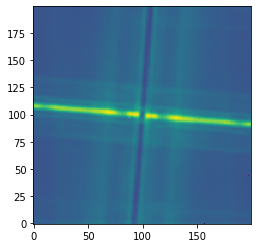

In [53]:
plt.imshow(bkg_rebuild,origin='lower',interpolation='none')
plt.show()

In [20]:
fi_1550

array([132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144,
       145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157,
       160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172,
       173, 174, 175, 184, 185, 186, 187])

In [ ]:
# Pyhton adaptation of IDL code by Anthony: miri_rdiloci.pro 2020/09/14 anthony.boccaletti@obspm.fr $
# PURPOSE : 
# exploit the Small Grid Dither of MIRI where the reference star is positioned on a 
# 9 points grid around the coronagraph 
# The target can also be observed with the SGD. 
# Build a reference image from the images of the reference star using the LOCI algorithm of Lafreniere et al. 2007

def LOCI_MIRI(cube, ref):
    n_cube = np.shape(cube)[0]
    n_ref  = np.shape(ref)[0]
    if n_ref == 9: #9-SGD
        for i in range(n_cube):
            p0=[1/9.,1/9.,1/9.,1/9.,1/9.,1/9.,1/9.,1/9.,1/9.]
            p = optimize.fmin(loci_func, cube[0], p0)
    return p


def miri_rdiloci(sci_cube, ref_cube, psf)




'''
FUNCTION miri_rdiloci,  tab, tabref, psf, xy0=xy0, fwhm=fwhm, pixscale = pixscale,  $
						Rmax=Rmax, wring=wring, Na= Na, g = g, silent = silent, $
 						resize = resize
	
	
taille = (size(tab))[1]		;; size of the image of the target 
Nframes = (size(tab))[3]	;; number of frames of the target

if not keyword_set(xy0)  then xy0 = [taille/2.,taille/2]	;; in pixels
if not keyword_set(fwhm) then fwhm = 0.06		;; in arcsec
if not keyword_set(Rmax) then Rmax = 2.5		;; in arcsec
if not keyword_set(wring)then wring = 2.0		;; in fwhm
if (not keyword_set(Na)) then Na = 300.			;; in fwhm
;if Na lt 25. 			 then Na = 1.						;; in fwhm
if (not keyword_set(g))  then g = 1.	

Rmin=0.
nbring = round( (Rmax-Rmin) /(wring*fwhm) )	;; number of rings to consider

;; redefine array size to restrain the calculation on a smaller number of pixels
if keyword_set(resize) then begin
  tailleini = taille
  tabadifin = fltarr(tailleini,tailleini) ;; final full image
  taille = round(2*Rmax/pixscale) + (round(2*Rmax/pixscale) mod 2)  ;; adapt array size with even size
  tab = tab[tailleini/2.-taille/2.:tailleini/2.+taille/2.-1,tailleini/2.-taille/2.:tailleini/2.+taille/2.-1,*]
  tabref = tabref[tailleini/2.-taille/2.:tailleini/2.+taille/2.-1,tailleini/2.-taille/2.:tailleini/2.+taille/2.-1,*]
  xy0 = xy0 - [tailleini/2.-taille/2.,tailleini/2.-taille/2.]
  tabadi = fltarr(taille,taille)  ;; output sub-image

  psf = psf [tailleini/2.-taille/2.:tailleini/2.+taille/2.-1,tailleini/2.-taille/2.:tailleini/2.+taille/2.-1]
endif else tabadi = fltarr(taille,taille)

;; define the center of the PSF
  tmp = gauss2dfit(psf,param_psf)
  xypsf = [param_psf[4],param_psf[5]]
  maskpsf = shift( dist(taille) lt 32.,xypsf[0],xypsf[1])
							
;; iterate on ring index
for l = 0, nbring-1 do begin

	sep = Rmin + l*wring*fwhm		;; mean radius of each ring
	
	;; make ring
	ring=shift( (dist(taille) ge (sep - wring*fwhm/2.)/pixscale) $
		 	  * (dist(taille) le (sep + wring*fwhm/2.)/pixscale),taille/2,taille/2)

    dummy = fltarr(taille,taille,nframes)  ;; intermediate cube 

	for n = 0, Nframes-1 do begin

        if not keyword_set(silent) then  print,'separation [arcsec] :',sep
  
  	    ;; determine number of sectors
		if Na ne 1. then begin
	      Dphi = (1./(g/2.+2*sep/fwhm*sqrt(g/(!pi*Na)))) *180/!pi  ;; in degree from Lafreniere
	      ndphi = round(360./Dphi)	;; nb of sectors
	      ;; size of optimization ring
	      Dr = sqrt(!pi*Na*fwhm^2./4.) ;; radial size of opti subsection in arcsec
		endif else begin
	      Lring = 8.
	      ndphi = round(2*!pi*sep / (Lring*fwhm))
	    endelse
	    	    
	    ;; determine obj and ref frames
	         ; baseline case
  	        obj = (tab[*,*,n])     ;; target image
  	        ref = (tabref[*,*,*])  ;; reference cube
  	    	Nframesref = (size(tabref))[3]  ;; number of frames for the reference

	    ;; normalize intensity of the reference to the object : NOT NECESSARY IN THE TEST WHERE OBJ and REF HAVE THE SAME FLUX
		refmean = (moment(ref,dim=3))[*,*,0]
		;ref = ref/total(refmean)*total(obj)

  	    ;; iterate on sector index
        for phi=0,ndphi-1 do begin 
 
 		  ; draw a sector of angular size Dphi	
          sector = dosector_new(taille=taille,xc=taille/2,yc=taille/2,td=phi*360./ndphi,tf=(phi+1.)*360./ndphi)

		  if Na ne 1. then begin
		   	;; ringopti includes ring
			ringopti=shift( (dist(taille) ge (sep - wring*fwhm/2.)/pixscale) $
		 	  * (dist(taille) le (sep- wring*fwhm/2. + Dr)/pixscale),taille/2,taille/2)   ;; larger ring for optimization
		  endif else 	ringopti = ring

		  pla = shift(psf,sep/pixscale*cos((phi+1./2)*360./ndphi*!pi/180.),sep/pixscale*sin((phi+1./2)*360./ndphi*!pi/180.))              ;; probe planet
 		  maskpsf = shift(psf gt 0.2,sep/pixscale*cos((phi+1./2)*360./ndphi*!pi/180.),sep/pixscale*sin((phi+1./2)*360./ndphi*!pi/180.))   ;; probe planet

		  mask = where (ringopti*sector eq 1.)    ;; select pixels of interest in sector*ring
		 
		  if n_elements(mask) gt 1. then begin    ;; check if sector*ring is not empty
		 
		  npix_mask=n_elements(mask)
		  
		 	 obj_phi = obj[mask]		;; select pixels on target image
		  	 ref_phi = fltarr(npix_mask,Nframesref) 
  		 	 for k=0,Nframesref-1 do begin
  		 	   tmp = ref[*,*,k]
  		  	   ref_phi[*,k] = tmp[mask]	;; select pixels on reference cube
 	         endfor	      
 	        
 	        ;; solve A.x = B <=> At.A.x = At.B to make the square matrix
 		  	;; matrix of products
		  	A = ref_phi ## transpose(ref_phi)
		  	B = reform(ref_phi ## transpose(obj_phi))	; B = reform(ref_phi ## transpose(obj_phi), Nframesref)	
	  	
	  	
          	;; get coefficient, build reference frame and subtract. 
          	stattmp = 0.
      	  	coef = la_linear_equation(A,B,status=stattmp)  	      	  	 	  
  
    	  		  ;; build the linear combination from the reference cube with the coefficients 	  			  	
	     	  refsum   = fltarr(taille,taille)			
			  for k=0,Nframesref-1 do refsum += (ref[*,*,k]*coef[k])
			  ;; subtract reference image from target image
			  tmp = (obj - refsum)	*ring*sector	 	 			  

		  ;; same with point source for calibration purpose (rough)
		  sigma_zone = sqrt((moment(tmp(where(tmp ne 0))))[1])
		  pla_int = 5.*sigma_zone
		  objpla_phi = (obj+pla/max(pla)*pla_int)[mask] ;; select pixels on target + planet image
		  Bpla = reform(ref_phi ## transpose(objpla_phi),Nframesref)

		  stattmp = 0
        	  coef = la_linear_equation(A,Bpla,status=stattmp)
		  refsum   = fltarr(taille,taille)

		  for k=0,Nframesref-1 do refsum += (ref[*,*,k]*coef[k])		  
		  tmppla = (obj+(pla/max(pla)*pla_int) - refsum)	*ring*sector

		  ;; 
		  correc = max(tmppla * maskpsf) / max(pla/max(pla)*pla_int * maskpsf)
		  tmp=tmp / (correc > 1e-2)
	  
		  ;; stack frames
			dummy[*,*,n] += tmp
		  endif	
	    endfor ;; loop sectors
	
    endfor  ;; loop frames
  		 
 	tabadi += nacomediane(dummy) 
	;tabadi += nacosum(dummy)  /nbpos_adi

fin:

endfor  ;; loop rings

;; make big array
if keyword_set(resize) then  tabadifin[tailleini/2.-taille/2.:tailleini/2.+taille/2.-1,tailleini/2.-taille/2.:tailleini/2.+taille/2.-1] = tabadi else tabadifin = tabadi

;; and shift as input
if keyword_set(resize) then begin
	xy0 = xy0 + [tailleini/2.-taille/2.,tailleini/2.-taille/2.] 
	taille = tailleini
endif

tabadifin = shift_subpixel(tabadifin,   (taille/2-xy0[0]), (taille/2-xy0[1]))

return, tabadifin


END






'''



# ANALYSE DU GLOWSTICK

In [8]:
### F1550C
path_save = "/home/cperrot/Work/projet/JWST/Target/backgrounds/F1550C/glowstick/"
if not os.path.exists(path_save):
    os.makedirs(path_save)
saveformat = 'pdf' #'pdf' #'png'

ndim = 200
x0 = 120
y0 = 114

dx=5


mask=np.zeros((ndim+20,ndim+20))
mask[(ndim+20)//2-dx:(ndim+20)//2+dx,:]=1
#mask[:,(ndim+20)//2-dx:(ndim+20)//2+dx]=1
mask = ndimage.rotate(mask, 4.83544897, reshape=False, prefilter=False)
mask[np.where(mask < 0.99)] = math.nan
mask[np.where(mask >= 0.99)] = 1
mask = mask[(ndim+20)//2-ndim//2:(ndim+20)//2+ndim//2,(ndim+20)//2-ndim//2:(ndim+20)//2+ndim//2]

std_gs = np.empty([len(path_fi[fi_1550])])
med_gs = np.empty([len(path_fi[fi_1550])])

vmin=2
vmax=25
fig, axs = plt.subplots(5,7, figsize=(15, 10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()

for i in range(len(fi_1550)):
    bkg = fits.open(path_fi[fi_1550[i]])[1].data
    bkg = bkg[y0-ndim//2:y0+ndim//2,x0-ndim//2:x0+ndim//2]
    #bkg[np.where(bkg*mask > 15)] = math.nan
    bkg  = imp.sigma_clip_jwst(bkg,3)
    std_gs[i] = np.nanstd(bkg*mask)
    med_gs[i] = np.nanmedian(bkg*mask)
    axs[i].imshow(bkg*mask,origin='lower',interpolation='none',vmin=vmin,vmax=vmax)
    axs[i].get_yaxis().set_visible(False)
    axs[i].get_xaxis().set_visible(False)

#plt.show()
fig.savefig(path_save+'F1550C_glowstick_rate_images.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig)



fig=plt.figure(figsize=(12,12))
img=plt.imshow(bkg*mask,origin='lower',interpolation='none',vmin=vmin,vmax=vmax)
cax1 = fig.add_axes([0.91, 0.2, 0.02, 0.6])
cba1 = fig.colorbar(img, cax=cax1, orientation='vertical')
#plt.show()
fig.savefig(path_save+'F1550C_glowstick_with_mask_illustration.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig)



### median and std dev VS Index - glowstick

fig=plt.figure(figsize=(15,10))
plt.plot(index[fi_1550],std_gs,color="black",label="All")
plt.plot(index[fi_1550],std_gs,'o',color="black",ms=4,mew=1.25)
plt.ylabel('ADU',fontsize=12)
plt.xlabel('Obs Index',fontsize=12)
plt.legend(loc='upper right',fontsize='medium')
plt.ylim([3,4])
plt.grid()
plt.title("F1550C Glowstick Standard deviation")
fig.tight_layout()
#plt.show()
fig.savefig(path_save+'F1550C_glowstick_std_dev_vs_index.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig)

fig=plt.figure(figsize=(15,10))
plt.plot(index[fi_1550],med_gs,color="black",label="All")
plt.plot(index[fi_1550],med_gs,'o',color="black",ms=4,mew=1.25)
plt.ylabel('ADU',fontsize=12)
plt.xlabel('Obs Index',fontsize=12)
plt.legend(loc='upper right',fontsize='medium')
plt.ylim([15,20])
plt.grid()
plt.title("F1550C Glowstick Median")
fig.tight_layout()
#plt.show()
fig.savefig(path_save+'F1550C_glowstick_median_vs_index.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig)



### Median VS NGROUPS and Effective Exposure Time - glowstick



fig=plt.figure(figsize=(15,10))
plt.plot(ngroups[fi_1550],med_gs,'o',color="black",ms=4,mew=1.25,label="All")
plt.ylabel('ADU',fontsize=12)
plt.xlabel('N groups',fontsize=12)
plt.legend(loc='upper right',fontsize='medium')
plt.ylim([15,20])
plt.grid()
plt.title("F1550C Glowstick Median")
fig.tight_layout()
#plt.show()
fig.savefig(path_save+'F1550C_glowstick_median_vs_Ngroups.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig)

fig=plt.figure(figsize=(15,10))
plt.plot(eff_exp[fi_1550],med_gs,'o',color="black",ms=4,mew=1.25,label="All")
plt.ylabel('ADU',fontsize=12)
plt.xlabel('Effective Exposure Time',fontsize=12)
plt.legend(loc='upper right',fontsize='medium')
plt.ylim([15,20])
plt.grid()
plt.title("F1550C Glowstick Median")
fig.tight_layout()
#plt.show()
fig.savefig(path_save+'F1550C_glowstick_median_vs_Eff_exp_time.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig)



### std dev VS NGROUPS and Effective Exposure Time - glowstick




fig=plt.figure(figsize=(15,10))
plt.plot(ngroups[fi_1550],std_gs,'o',color="black",ms=4,mew=1.25,label="All")
plt.ylabel('ADU',fontsize=12)
plt.xlabel('N groups',fontsize=12)
plt.legend(loc='upper right',fontsize='medium')
plt.ylim([3,4])
plt.grid()
plt.title("F1550C Glowstick Standard deviation")
fig.tight_layout()
#plt.show()
fig.savefig(path_save+'F1550C_glowstick_std_dev_vs_Ngroups.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig)

fig=plt.figure(figsize=(15,10))
plt.plot(eff_exp[fi_1550],std_gs,'o',color="black",ms=4,mew=1.25,label="All")
plt.ylabel('ADU',fontsize=12)
plt.xlabel('Effective Exposure Time',fontsize=12)
plt.legend(loc='upper right',fontsize='medium')
plt.ylim([3,4])
plt.grid()
plt.title("F1550C Glowstick Standard deviation")
fig.tight_layout()
#plt.show()
fig.savefig(path_save+'F1550C_glowstick_std_dev_vs_Eff_exp_time.'+saveformat,format=saveformat,bbox_inches='tight')
plt.close(fig)

In [6]:
std_gs

array([3.48665157, 3.54982932, 3.55946628, 3.55990138, 3.54513547,
       3.54128535, 3.64989904, 3.6726501 , 3.62217779, 3.64170006,
       3.29990856, 3.31059776, 3.61037517, 3.61688913, 3.58915697,
       3.59157515, 3.59187572, 3.58357911, 3.4981369 , 3.49978491,
       3.4957555 , 3.50277288, 3.65996062, 3.65512807, 3.65691842,
       3.65749606, 3.60365953, 3.60563224, 3.45822376, 3.46412605,
       3.46740784, 3.46775836, 3.61787163, 3.61850569])

In [7]:
med_gs

array([18.86174965, 18.88574409, 17.7190609 , 17.717062  , 17.40877342,
       17.4428463 , 16.35823441, 16.32733154, 15.79718399, 15.80266619,
       19.75327682, 19.74422836, 16.34331894, 16.29782486, 17.74381828,
       17.73050499, 17.69018745, 17.67788506, 19.69862652, 19.69034195,
       19.67539406, 19.72311306, 16.77790451, 16.52372932, 16.45132637,
       16.45430183, 16.76981735, 16.71374893, 18.61843681, 18.90215302,
       18.6081295 , 18.91995049, 16.68112469, 16.68966293])

7.1503682136535645 1.5750327204474879
7.129761219024658 1.1904827332969163


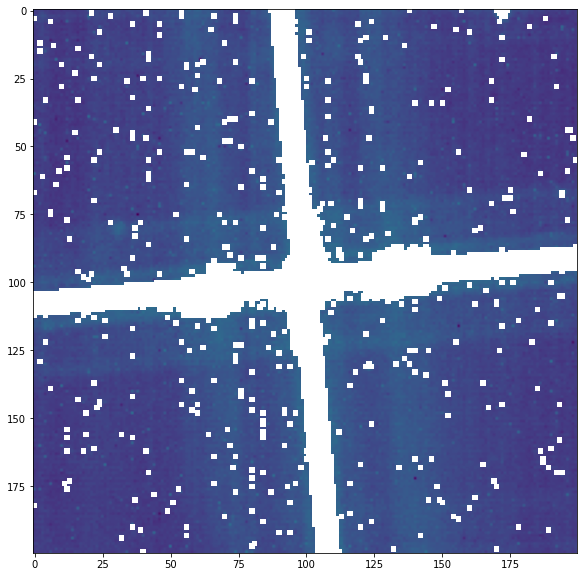

In [44]:
bkg = fits.open(path_fi[fi_1550[33]])[1].data
bkg = bkg[y0-ndim//2:y0+ndim//2,x0-ndim//2:x0+ndim//2]
med = np.nanmedian(bkg*mask)
std = np.nanstd(bkg*mask)
print(med,std)
print(med_q[4,33],std_q[4,33])
map_bp = np.where(bkg >= med+2*std) #+ np.where(bkg <= med-2*std)

bkg[map_bp] = math.nan

fig=plt.figure(figsize=(10,10))
plt.imshow(bkg*mask,vmin=2,vmax=25)
plt.show()

### marche mal

### Old analyse of the background - I keep it for the idea

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from scipy import ndimage
from scipy.optimize import curve_fit
from astropy.stats import sigma_clip
from astropy.io import fits
import glob

Loading of 9 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200


Text(0.5, 1.0, 'ERS')

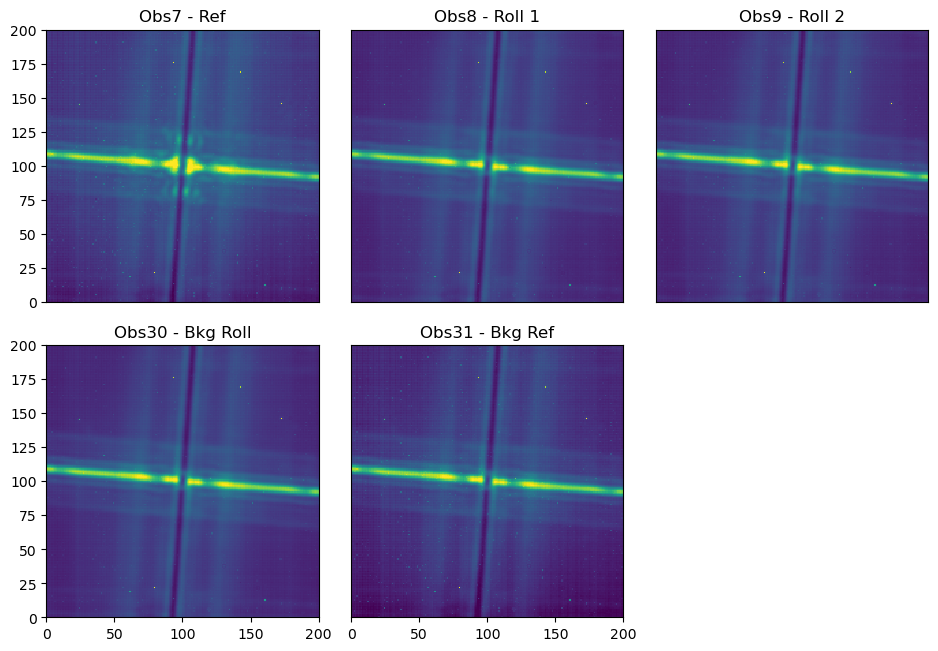

In [2]:
path_comm = "/home/cperrot/Work/raw/JWST/Target/Comm/"
path_ers  = "/home/cperrot/Work/raw/JWST/Target/ERS/1386/"
path_gto  = "/home/cperrot/Work/raw/JWST/Target/GTO/"
path_code = "/home/cperrot/Work/code/JWST/Target/GTO/"

dimx=288
dimy=224

newd=200

#comm 1045 - F1550C

fobs48 = "obs48_COR_F1550C" 


#ERS 1386 - HIP 65426 / HD141569 - F1550C
x0 = 120
y0 = 114
fers7 = "obs7_COR_F1550C" #ref
fers8 = "obs8_COR_F1550C" #roll1
fers9 = "obs9_COR_F1550C" #roll2
fers30 = "obs30_COR_F1550C" #bkg roll
fers31 = "obs31_COR_F1550C" #bkg ref

ers7, hers7   = imp.load_cube(path_ers+fers7+"/", "rate", xdim=newd , ydim=newd, x0=x0, y0=y0)
ers8, hers8   = imp.load_cube(path_ers+fers8+"/", "rate", xdim=newd , ydim=newd, x0=x0, y0=y0)
ers9, hers9   = imp.load_cube(path_ers+fers9+"/", "rate", xdim=newd , ydim=newd, x0=x0, y0=y0)
ers30, hers30 = imp.load_cube(path_ers+fers30+"/", "rate", xdim=newd , ydim=newd, x0=x0, y0=y0)
ers31, hers31 = imp.load_cube(path_ers+fers31+"/", "rate", xdim=newd , ydim=newd, x0=x0, y0=y0)
ers7  = imp.badpixel_corr(ers7)
ers8  = imp.badpixel_corr(ers8)
ers9  = imp.badpixel_corr(ers9)
ers30 = imp.badpixel_corr(ers30)
ers31 = imp.badpixel_corr(ers31)


vmin=5
vmax=25
fig1,[[sub1,sub2,sub3],[sub4,sub5,sub6]] = plt.subplots(nrows=2,ncols=3,figsize=(9,8))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
tmp1 = sub1.imshow(np.nanmedian(ers7,axis=0),origin='lower',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,newd,0,newd])
tmp2 = sub2.imshow(ers8,origin='lower',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,newd,0,newd])
tmp3 = sub3.imshow(ers9,origin='lower',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,newd,0,newd])
tmp4 = sub4.imshow(np.nanmedian(ers30,axis=0),origin='lower',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,newd,0,newd])
tmp5 = sub5.imshow(np.nanmedian(ers31,axis=0),origin='lower',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,newd,0,newd])
sub2.get_yaxis().set_visible(False)
sub3.get_yaxis().set_visible(False)
sub5.get_yaxis().set_visible(False)
sub1.get_xaxis().set_visible(False)
sub2.get_xaxis().set_visible(False)
sub3.get_xaxis().set_visible(False)
sub6.set_visible(False)
sub1.set_title("Obs7 - Ref")
sub2.set_title("Obs8 - Roll 1")
sub3.set_title("Obs9 - Roll 2")
sub4.set_title("Obs30 - Bkg Roll")
sub5.set_title("Obs31 - Bkg Ref")
plt.title('ERS')



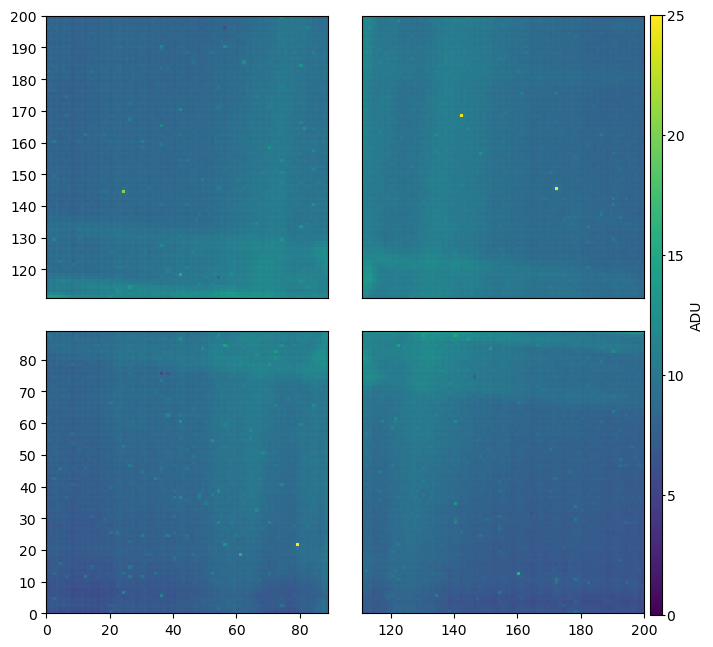

In [3]:
dx=11
q1=[100+dx, -1, 0, 100-dx]
q2=[100+dx, -1, 100+dx, -1]
q3=[0, 100-dx, 0, 100-dx]
q4=[0, 100-dx,100+dx, -1]
qn=[q1,q2,q3,q4]

mask=np.zeros((newd,newd))+1.
mask[newd//2-dx:newd//2+dx,:]=0
mask[:,newd//2-dx:newd//2+dx]=0

vmin=0
vmax=25
fig1,[[sub1,sub2],[sub3,sub4]] = plt.subplots(nrows=2,ncols=2,figsize=(6.1,8))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
tmp1 = sub1.imshow(ers7[1,newd//2+dx:,0:newd//2-dx],origin='lower',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,newd//2-dx,newd//2+dx,newd])
tmp2 = sub2.imshow(ers7[1,newd//2+dx:,newd//2+dx:],origin='lower',interpolation='none',vmin=vmin,vmax=vmax,extent=[newd//2+dx,newd,newd//2+dx,newd])
tmp3 = sub3.imshow(ers7[1,0:newd//2-dx,0:newd//2-dx],origin='lower',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,newd//2-dx,0,newd//2-dx])
tmp4 = sub4.imshow(ers7[1,0:newd//2-dx,newd//2+dx:],origin='lower',interpolation='none',vmin=vmin,vmax=vmax,extent=[newd//2+dx,newd,0,newd//2-dx])
sub2.get_yaxis().set_visible(False)
sub4.get_yaxis().set_visible(False)
sub1.get_xaxis().set_visible(False)
sub2.get_xaxis().set_visible(False)
cax  = fig1.add_axes([1, 0.12, 0.02, 0.75])
cbar = fig1.colorbar(tmp3, cax=cax, orientation='vertical')
cbar.set_label('ADU',fontsize=10)
cbar.ax.tick_params(length=2,pad=1,labelsize=10)
plt.show()

In [2]:
def bkg_log10(x,a,b):
    """Y = A + B * log10(x)"""
    return a+b*np.log10(x)

In [3]:
#definition of the path

path_raw_comm  = "/home/cperrot/Work/raw/JWST/Target/Comm/"
path_raw_ers  = "/home/cperrot/Work/raw/JWST/Target/ERS/"
path_code = "/home/cperrot/Work/code/JWST/Target/GTO/"
path_save = "/home/cperrot/Work/projet/JWST/Target/GTO/Bkg_analyse/"

#background de 1140C

folder="1140C/"

#comm 1045
prop="1045"
bkg_1=path_raw_comm+prop+"/jw0"+prop+f"{48:03}"+"001_02101_"+f"{1:05}"+"_mirimage/"
bkg_2=path_raw_comm+prop+"/jw0"+prop+f"{65:03}"+"001_02101_"+f"{1:05}"+"_mirimage/"
bkg_3=path_raw_comm+prop+"/jw0"+prop+f"{65:03}"+"001_02101_"+f"{2:05}"+"_mirimage/"
bkg_4=path_raw_comm+prop+"/jw0"+prop+f"{65:03}"+"001_02101_"+f"{3:05}"+"_mirimage/"
bkg_5=path_raw_comm+prop+"/jw0"+prop+f"{65:03}"+"001_02101_"+f"{4:05}"+"_mirimage/"
bkg_6=path_raw_comm+prop+"/jw0"+prop+f"{81:03}"+"001_02101_"+f"{1:05}"+"_mirimage/"
prop="HIP65426"
bkg_7=path_raw_ers+prop+"/obs28_COR_F1140C/"
bkg_8=path_raw_ers+prop+"/obs29_COR_F1140C/"
bkg_9=path_raw_ers+prop+"/obs34_COR_F1140C/"
bkg_10=path_raw_ers+prop+"/obs35_COR_F1140C/"

In [4]:
img1, head1 = imp.load_cube(bkg_1, "rateints", xdim=200, ydim=200, x0=120, y0=112)
img2, head2 = imp.load_cube(bkg_2, "rateints", xdim=200, ydim=200, x0=120, y0=112)
img3, head3 = imp.load_cube(bkg_3, "rateints", xdim=200, ydim=200, x0=120, y0=112)
img4, head4 = imp.load_cube(bkg_4, "rateints", xdim=200, ydim=200, x0=120, y0=112)
img5, head5 = imp.load_cube(bkg_5, "rateints", xdim=200, ydim=200, x0=120, y0=112)
img6, head6 = imp.load_cube(bkg_6, "rateints", xdim=200, ydim=200, x0=120, y0=112)
tmp, head7 = imp.load_cube(bkg_7, "rateints", xdim=200, ydim=200, x0=120, y0=112)
img7 = tmp[0,:,:,:]
img8 = tmp[1,:,:,:]
tmp, head8 = imp.load_cube(bkg_8, "rateints", xdim=200, ydim=200, x0=120, y0=112)
img9 = tmp[0,:,:,:]
img10 = tmp[1,:,:,:]
'''
tmp, head9 = imp.load_cube(bkg_9, "rate", xdim=200, ydim=200, x0=120, y0=112)
img11 = tmp[0,:,:,:]
img12 = tmp[1,:,:,:]
tmp, head10 = imp.load_cube(bkg_10, "rate", xdim=200, ydim=200, x0=120, y0=112)
img13 = tmp[0,:,:,:]
img14 = tmp[1,:,:,:]
'''
print("1: "+str(img1.shape))
print("2: "+str(img2.shape))
print("3: "+str(img3.shape))
print("4: "+str(img4.shape))
print("5: "+str(img5.shape))
print("6: "+str(img6.shape))
print("7: "+str(img7.shape))
print("8: "+str(img8.shape))
print("9: "+str(img9.shape))
print("10: "+str(img10.shape))
'''
print("11: "+str(img11.shape))
print("12: "+str(img12.shape))
print("13: "+str(img13.shape))
print("14: "+str(img14.shape))
'''

1: (10, 200, 200)
2: (21, 200, 200)
3: (21, 200, 200)
4: (21, 200, 200)
5: (21, 200, 200)
6: (21, 200, 200)
7: (41, 200, 200)
8: (41, 200, 200)
9: (10, 200, 200)
10: (10, 200, 200)


In [5]:


label = ["Obs 48", "Obs 65 - 1", "Obs 65 - 2", "Obs 65 - 3", "Obs 65 - 4", "Obs 81", "Obs 28 - 1", "Obs 28 - 2", "Obs 29 - 1", "Obs 29 - 2"]#, "Obs 34 - 1", "Obs 34 - 2", "Obs 35 - 1", "Obs 35 - 2"]
img = [img1, img2, img3, img4, img5, img6, img7, img8, img9, img10]#, img11, img12, img13, img14]

dx=10
q1=[100+dx, -1, 0, 100-dx]
q2=[100+dx, -1, 100+dx, -1]
q3=[0, 100-dx, 0, 100-dx]
q4=[0, 100-dx,100+dx, -1]
qn=[q1,q2,q3,q4]
fcolor=['blue','orange','green','red','purple','brown','pink','grey', 'olive', 'cyan','black','yellow','indigo','darkblue']
qname = ['Quadran Upper Left','Quadran Upper Right', 'Quadran Lower Left','Quadran Lower Right']


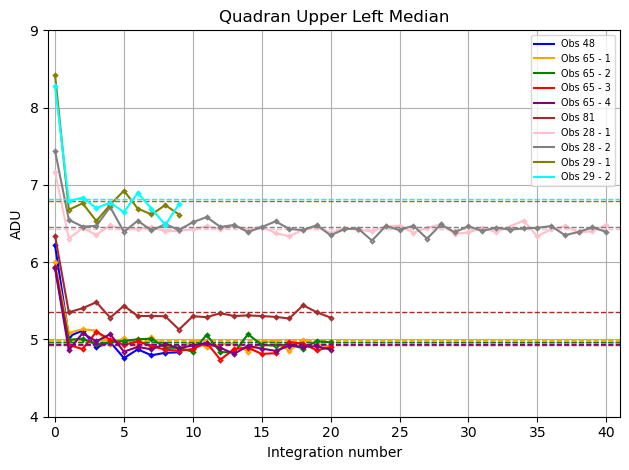

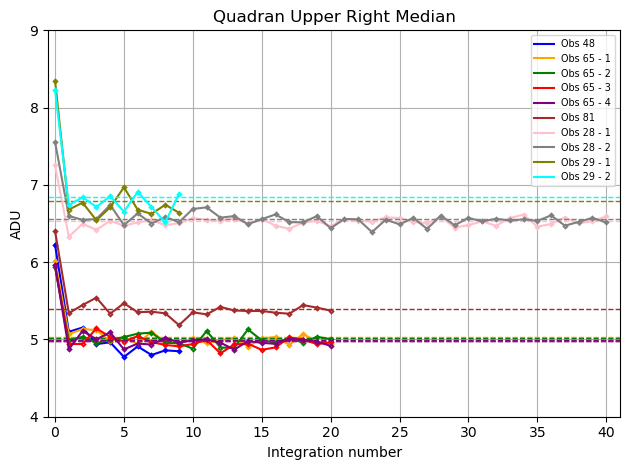

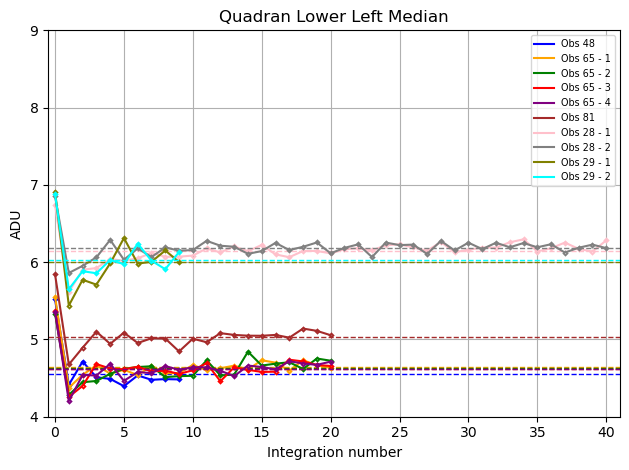

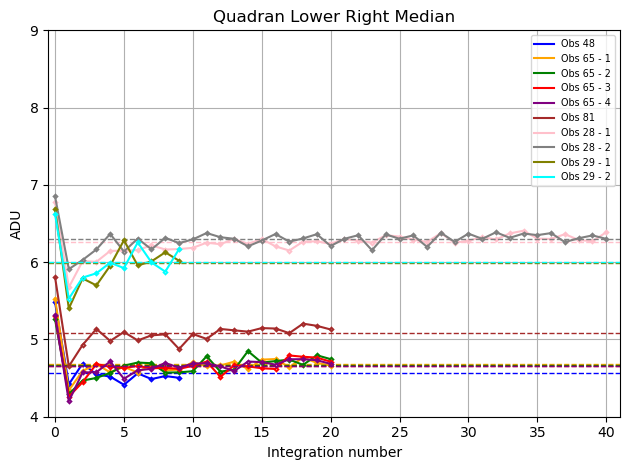

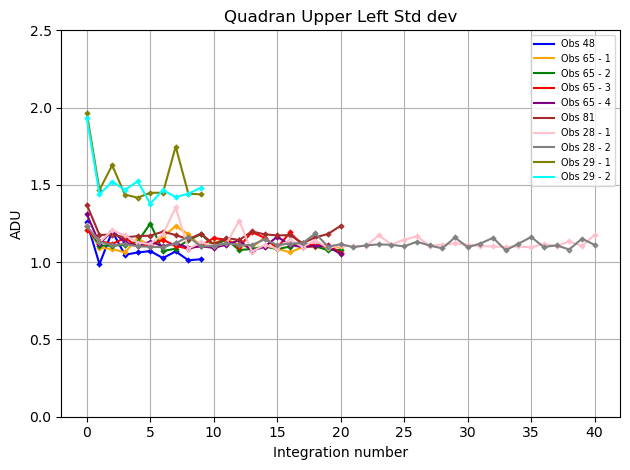

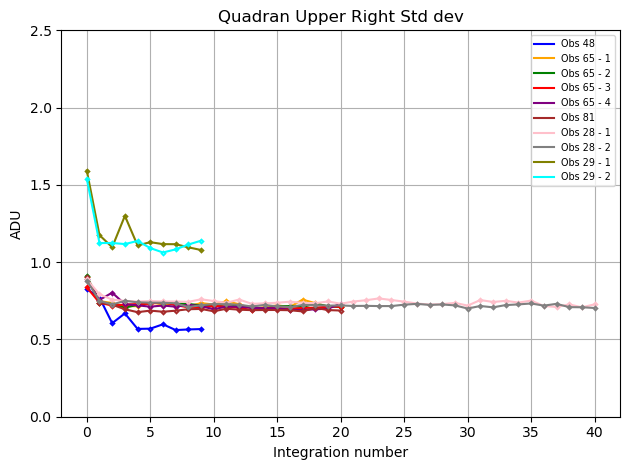

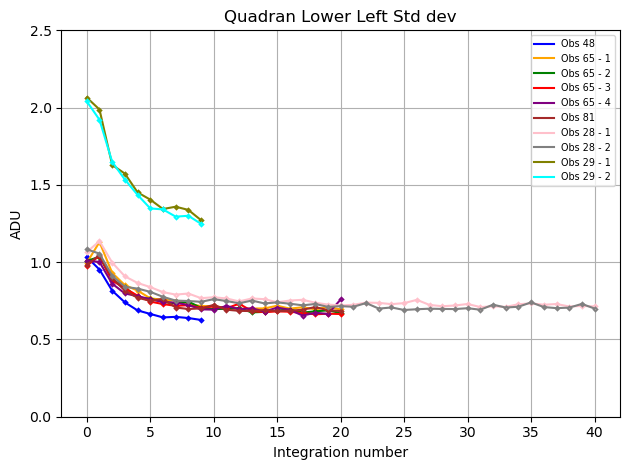

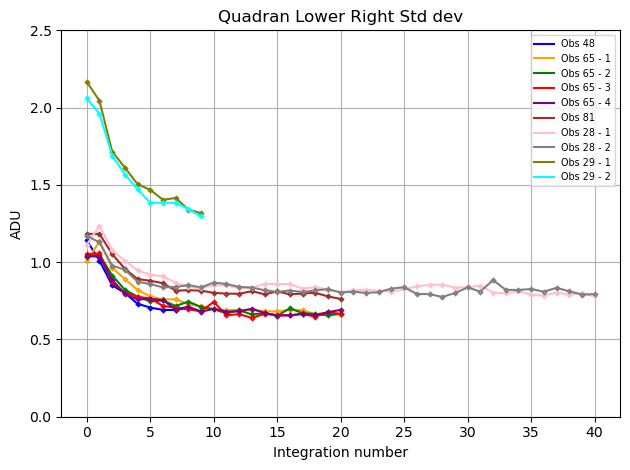

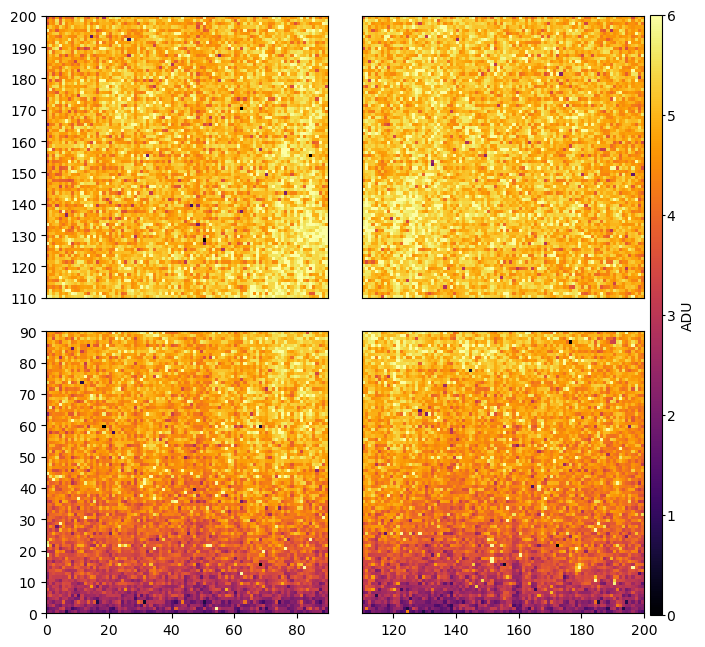

In [9]:

#MEDIAN
for j in range(4):
    fig=plt.figure()
    for i in range(len(img)):
        med  = np.median(img[i][:,qn[j][0]:qn[j][1],qn[j][2]:qn[j][3]],axis=(1,2))
        mean = np.mean(img[i][:,qn[j][0]:qn[j][1],qn[j][2]:qn[j][3]],axis=(1,2))
        plt.plot(med,'D',color=fcolor[i],ms=2,mew=1.25,markerfacecolor='None')
        plt.plot(med,color=fcolor[i],label=label[i])
        medfull = np.median(img[i][:,qn[j][0]:qn[j][1],qn[j][2]:qn[j][3]])
        plt.plot([-1,100],[medfull,medfull],'--',color=fcolor[i],lw=1)
    plt.ylabel('ADU',fontsize=10)
    plt.xlabel('Integration number',fontsize=10)
    plt.legend(loc='upper right',fontsize='x-small')
    plt.ylim([4,9])
    plt.xlim([-0.5,41])
    plt.grid()
    plt.title(qname[j]+" Median")
    fig.tight_layout()
    #fig.savefig(path_save+folder+'median_bkg_'+qname[j]+'F1140_Comm_ERS.pdf',format='pdf',bbox_inches='tight')
    #plt.close(fig)
    plt.show()

for j in range(4):
    fig=plt.figure()
    for i in range(len(img)):
        stdd = np.std(img[i][:,qn[j][0]:qn[j][1],qn[j][2]:qn[j][3]],axis=(1,2))
        plt.plot(stdd,'D',color=fcolor[i],ms=2,mew=1.25,markerfacecolor='None')
        plt.plot(stdd,color=fcolor[i],label=label[i])
    plt.ylabel('ADU',fontsize=10)
    plt.xlabel('Integration number',fontsize=10)
    plt.legend(loc='upper right',fontsize='x-small')
    plt.ylim([0,2.5])
    plt.grid()
    plt.title(qname[j]+" Std dev")
    fig.tight_layout()
    #fig.savefig(path_save+folder+'Std_dev_bkg_'+qname[j]+'F1140_Comm_ERS.pdf',format='pdf',bbox_inches='tight')
    #plt.close(fig)
    plt.show()

dx=10
mask=np.zeros((200,200))+1.
mask[100-dx:100+dx,:]=0
mask[:,100-dx:100+dx]=0

vmin=0
vmax=6
fig1,[[sub1,sub2],[sub3,sub4]] = plt.subplots(nrows=2,ncols=2,figsize=(6.1,8))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
tmp1 = sub1.imshow(img1[1,100+dx:,0:100-dx],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,100-dx,100+dx,200])
tmp2 = sub2.imshow(img1[1,100+dx:,100+dx:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=[100+dx,200,100+dx,200])
tmp3 = sub3.imshow(img1[1,0:100-dx,0:100-dx],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,100-dx,0,100-dx])
tmp4 = sub4.imshow(img1[1,0:100-dx,100+dx:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=[100+dx,200,0,100-dx])
sub2.get_yaxis().set_visible(False)
sub4.get_yaxis().set_visible(False)
sub1.get_xaxis().set_visible(False)
sub2.get_xaxis().set_visible(False)
cax  = fig1.add_axes([1, 0.12, 0.02, 0.75])
cbar = fig1.colorbar(tmp3, cax=cax, orientation='vertical')
cbar.set_label('ADU',fontsize=10)
cbar.ax.tick_params(length=2,pad=1,labelsize=10)
#fig1.savefig(path_save+folder+'bkg_4quadran_F1140_Comm_ERS.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig1)
plt.show()

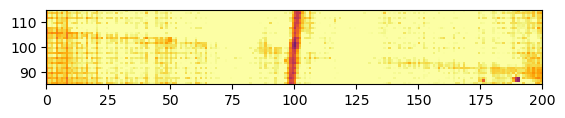

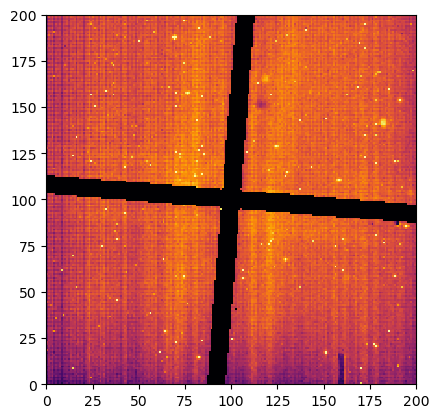

In [10]:

dx = 15
gs = [0,200,100-dx,100+dx]

medimg1=np.median(img8[1:,:,:],axis=0)
#medimg1=img1[3,:,:] #pas de median
vmin=3
vmax=6.5
fig1 = plt.figure()
plt.imshow(medimg1[100-dx:100+dx,0:200],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,200,100-dx,100+dx])
#plt.imshow(img1[1,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)#,extent=gs)
#fig1.savefig(path_save+folder+'glow_stick_F1140_Comm_ERS.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig1)
plt.show()

dx = 5
mask_croix = np.zeros((220,220))#+1.
mask_croix[:,110-dx:110+dx] = 1
mask_croix[110-dx:110+dx,:] = 1
xdeg=4.5
maskgs=ndimage.rotate(mask_croix,xdeg,reshape=False)
maskgs[np.where(maskgs >= 0.5)] = 1
maskgs[np.where(maskgs < 0.5)] = 0
#maskgs_inv= maskgs*(-1.)+1.
maskgs_inv = maskgs[10:210,10:210] < 1

vmin=4
vmax=8
fig1 = plt.figure()
plt.imshow(maskgs_inv*medimg1,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,200,0,200])
#fig1.savefig(path_save+folder+'mask_glow_stick_F1140_Comm_ERS.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig1)
plt.show()

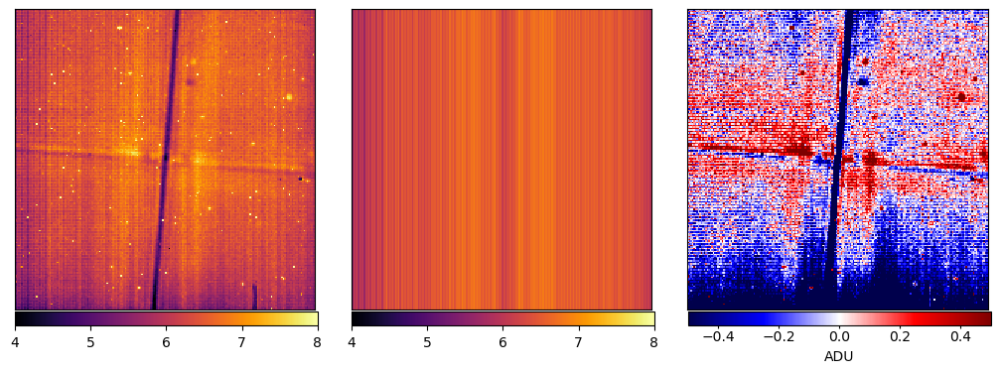

In [12]:

med_masked = maskgs_inv*medimg1
res = np.zeros((200,200))
deg_poly = 2
#median_verticale
for i in range(200):
	tmp = med_masked[:,i]
	tmp_mask = maskgs_inv[:,i]
	#popt, pcov = curve_fit(bkg_log10, range(200), tmp, p0=[np.median(tmp[0:10]), 0.5])
	#fit = bkg_log10(range(200),popt[0],popt[1])
	#res[:,i] = fit
	res[:,i] = np.median(sigma_clip(tmp[tmp_mask], sigma=2, masked=False)) #np.median(tmp) ### faire un sigma clipping poru virer les pixel chaud
	#z = np.poly1d(np.polyfit(range(200),tmp,deg_poly))
	#res[:,i] = z(range(200))

#median_horizontale
med_masked = maskgs_inv*(medimg1-res)
resh = np.zeros((200,200))
for i in range(200):
	tmp = med_masked[i,:]
	tmp_mask = maskgs_inv[i,:]
	#popt, pcov = curve_fit(bkg_log10, range(200), tmp, p0=[np.median(tmp[0:10]), 0.5])
	#fit = bkg_log10(range(200),popt[0],popt[1])
	#res[:,i] = fit
	resh[i,:] = np.median(sigma_clip(tmp[tmp_mask], sigma=2, masked=False)) #np.median(tmp) ### faire un sigma clipping poru virer les pixel chaud
	#z = np.poly1d(np.polyfit(range(200),tmp,deg_poly))
	#res[:,i] = z(range(200))
resh=0

vmin=4
vmax=8
fig,[sub1,sub2,sub3] = plt.subplots(nrows=1,ncols=3,figsize=(10,4))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
tmp1 = sub1.imshow(medimg1,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,200,0,200])
tmp2 = sub2.imshow(res+resh,origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,200,0,200])
tmp3 = sub3.imshow(medimg1-(res+resh),origin='lower',cmap='seismic',interpolation='none',vmin=-0.5,vmax=.5,extent=[0,200,0,200])
sub1.get_yaxis().set_visible(False)
sub2.get_yaxis().set_visible(False)
sub3.get_yaxis().set_visible(False)
sub1.get_xaxis().set_visible(False)
sub2.get_xaxis().set_visible(False)
sub3.get_xaxis().set_visible(False)
cax1  = fig.add_axes([0.01, 0.076, 0.305, 0.035])
cbar = fig.colorbar(tmp1, cax=cax1, orientation='horizontal')
cax2  = fig.add_axes([0.349, 0.076, 0.305, 0.035])
cbar = fig.colorbar(tmp2, cax=cax2, orientation='horizontal')
cax3  = fig.add_axes([0.688, 0.076, 0.305, 0.035])
cbar = fig.colorbar(tmp3, cax=cax3, orientation='horizontal')
cbar.set_label('ADU',fontsize=10)
cbar.ax.tick_params(length=2,pad=1,labelsize=10)
#fig.savefig(path_save+folder+'bkg_data_model_F1140_Comm_ERS.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()

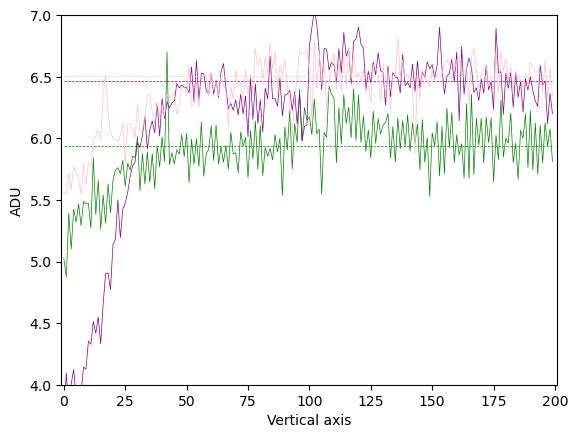

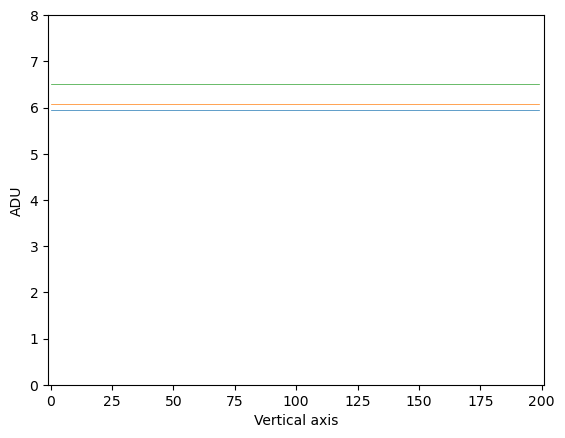

In [13]:
### fitter un polynome sur les colonnes de l'image pour interpoler le bkg sur le GS
### retirer le fit polynomiale pour n'avoir que le GS


fig = plt.figure()
for i in [2,92,150]:
	plt.plot(range(200),medimg1[:,i],lw=0.5,color=fcolor[i%8])
	plt.plot(range(200),res[:,i],'--',lw=0.5,color=fcolor[i%8])
	plt.ylabel('ADU')
	plt.xlabel('Vertical axis')
	plt.xlim([-1,201])
	plt.ylim([4,7])
#fig.savefig(path_save+folder+'Vertical_axis_cut.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()

fig = plt.figure()
for i in [2,100,150]:
	plt.plot(range(200),res[:,i],lw=0.5)
	plt.ylabel('ADU')
	plt.xlabel('Vertical axis')
	plt.xlim([-1,201])
	plt.ylim([0,8])
#fig.savefig(path_save+folder+'Vertical_axis_cut_fit.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()



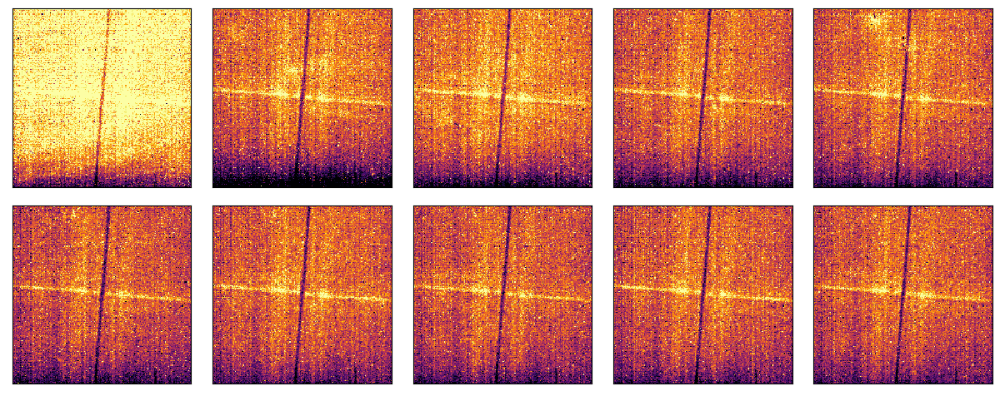

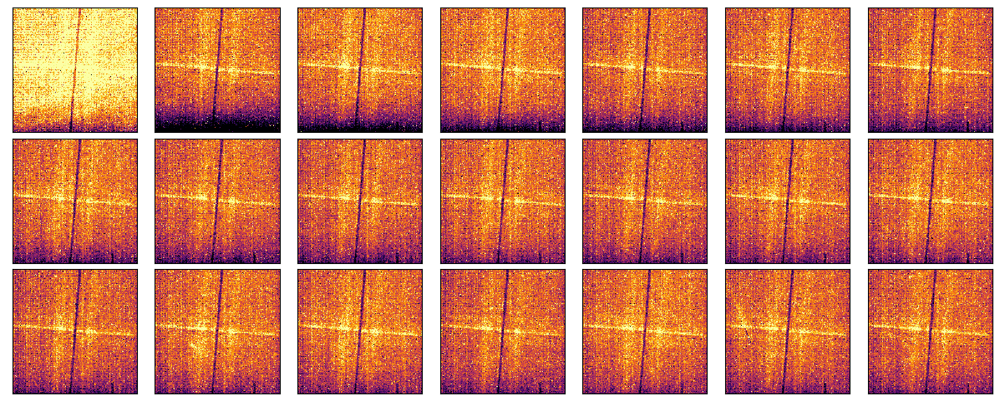

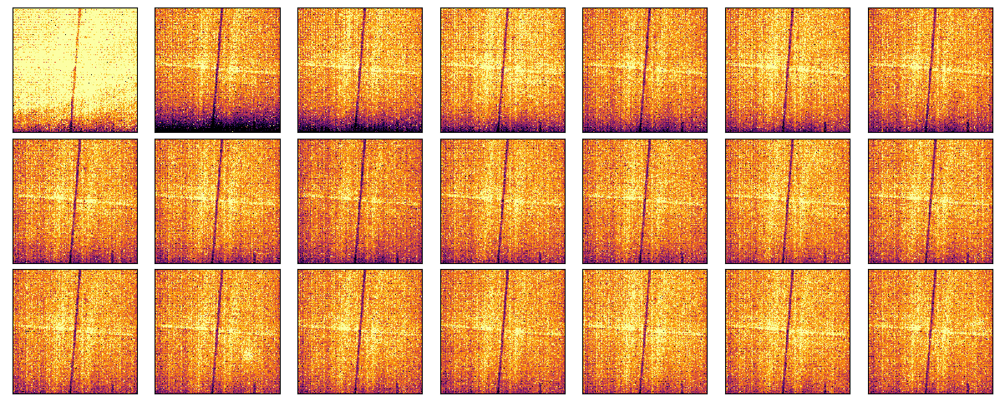

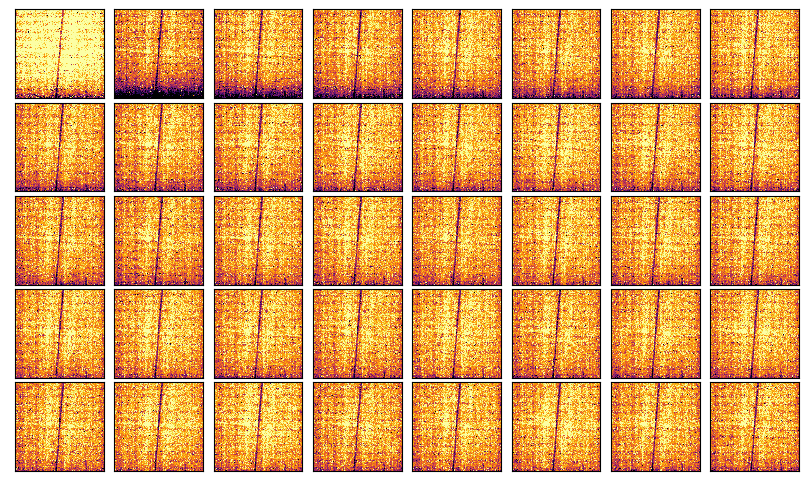

In [15]:
#### PLOT DES IMAGES DE BKG


#OBS 48
vmin=3
vmax=6
fig, axs = plt.subplots(2,5, figsize=(12, 6))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()
for i in range(10):
	axs[i].imshow(img1[i,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
	axs[i].get_yaxis().set_visible(False)
	axs[i].get_xaxis().set_visible(False)
#fig.savefig(path_save+folder+'bkg_obs_48_F1140_Comm_ERS.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()

#OBS 65 - 1
vmin=3
vmax=6
fig, axs = plt.subplots(3,7, figsize=(12, 6))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()
for i in range(21):
	axs[i].imshow(img2[i,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
	axs[i].get_yaxis().set_visible(False)
	axs[i].get_xaxis().set_visible(False)
#fig.savefig(path_save+folder+'bkg_obs_65_1_F1140_Comm_ERS.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()


#OBS 81
vmin=3
vmax=6
fig, axs = plt.subplots(3,7, figsize=(12, 6))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()
for i in range(21):
	axs[i].imshow(img6[i,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
	axs[i].get_yaxis().set_visible(False)
	axs[i].get_xaxis().set_visible(False)
#fig.savefig(path_save+folder+'bkg_obs_81_F1140_Comm_ERS.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()


#OBS 28 - 1
vmin=4
vmax=7
fig, axs = plt.subplots(5,8, figsize=(8, 6))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()
for i in range(40):
	axs[i].imshow(img7[i,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
	axs[i].get_yaxis().set_visible(False)
	axs[i].get_xaxis().set_visible(False)
#plt.axis('off')
#fig.savefig(path_save+folder+'bkg_obs_28_1_F1140_Comm_ERS.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()



1: (60, 200, 200)
2: (60, 200, 200)
3: (9, 19, 200, 200)
4: (60, 200, 200)
5: (60, 200, 200)
6: (19, 200, 200)
7: (19, 200, 200)


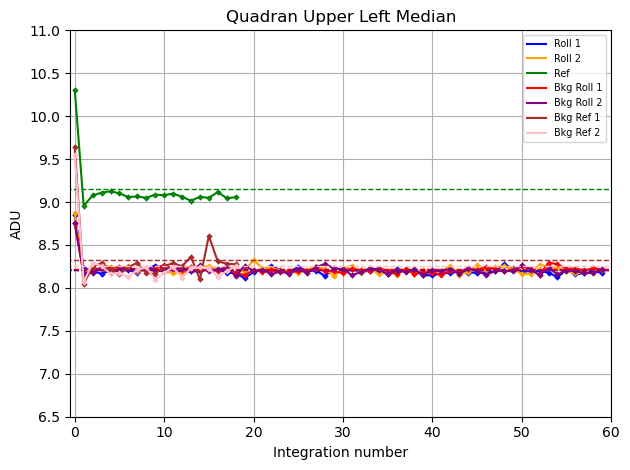

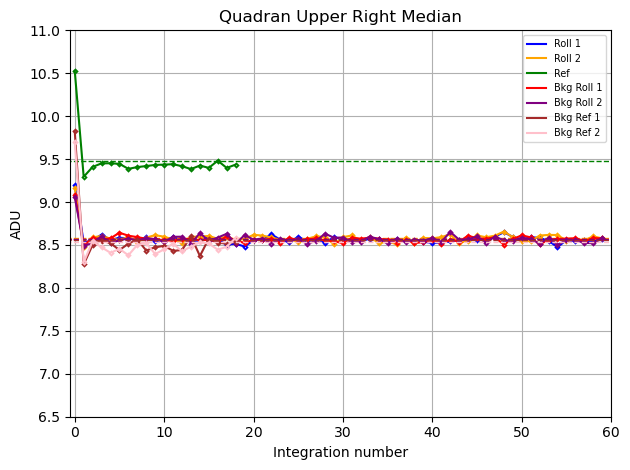

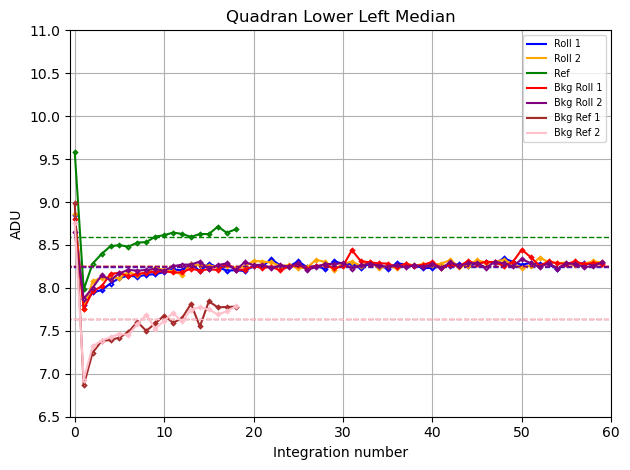

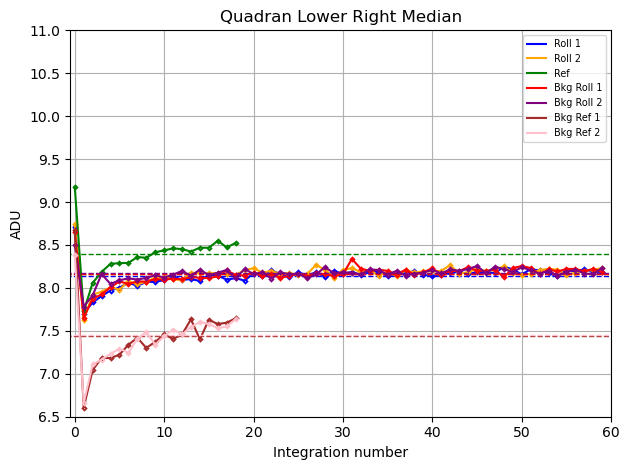

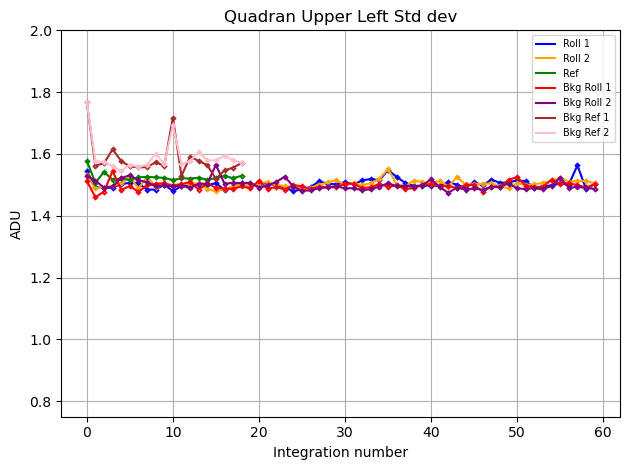

...

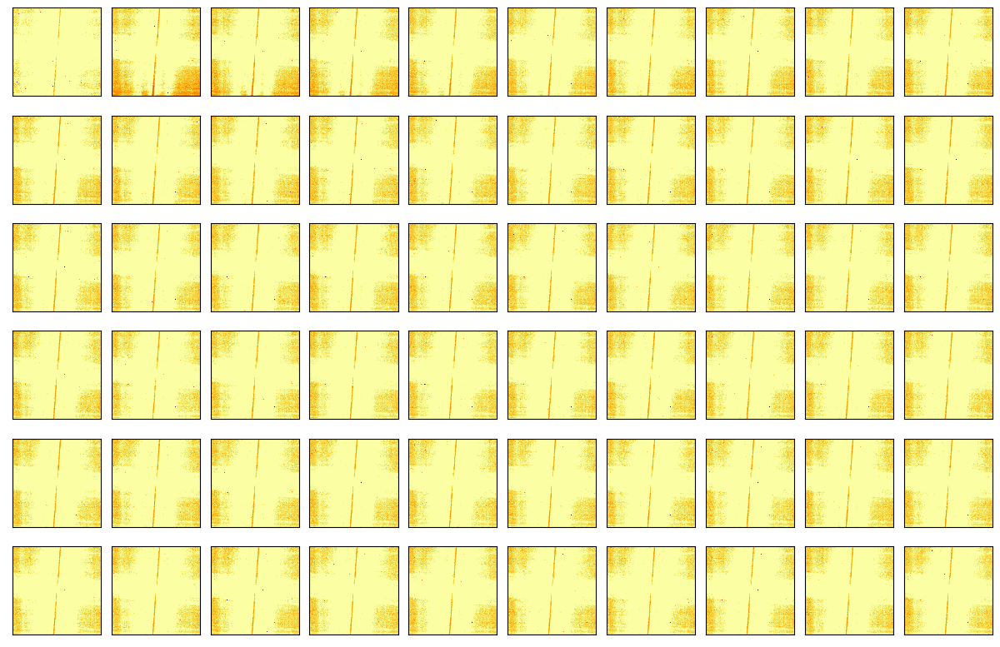

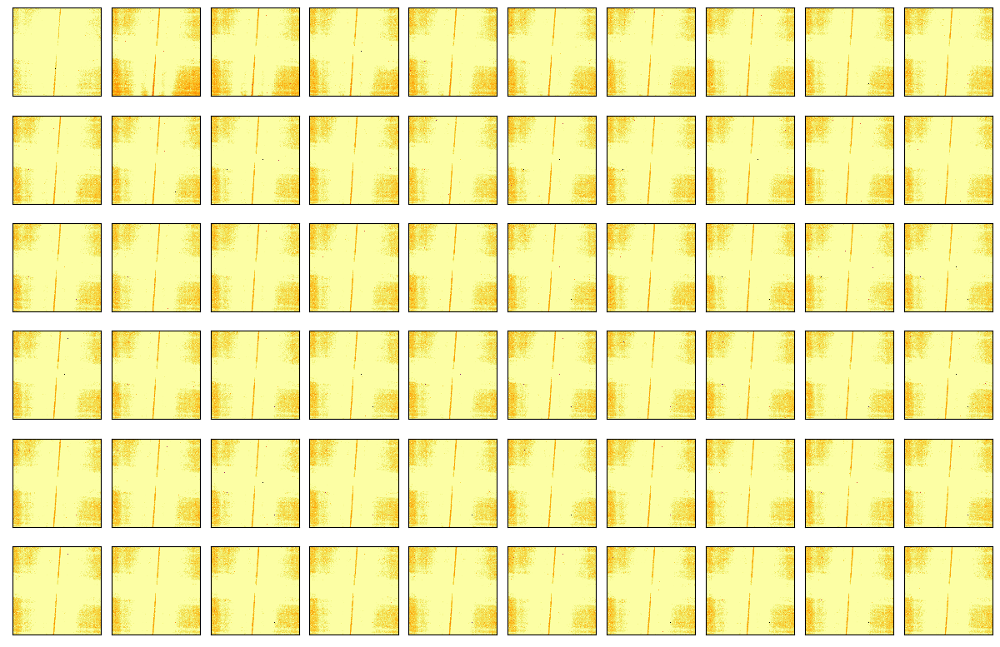

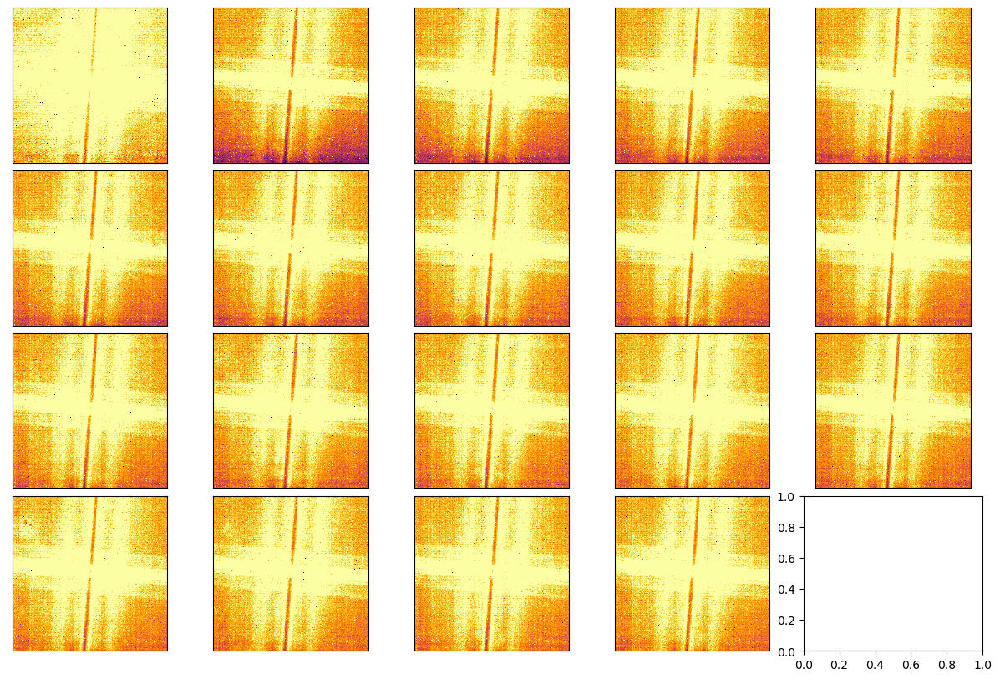

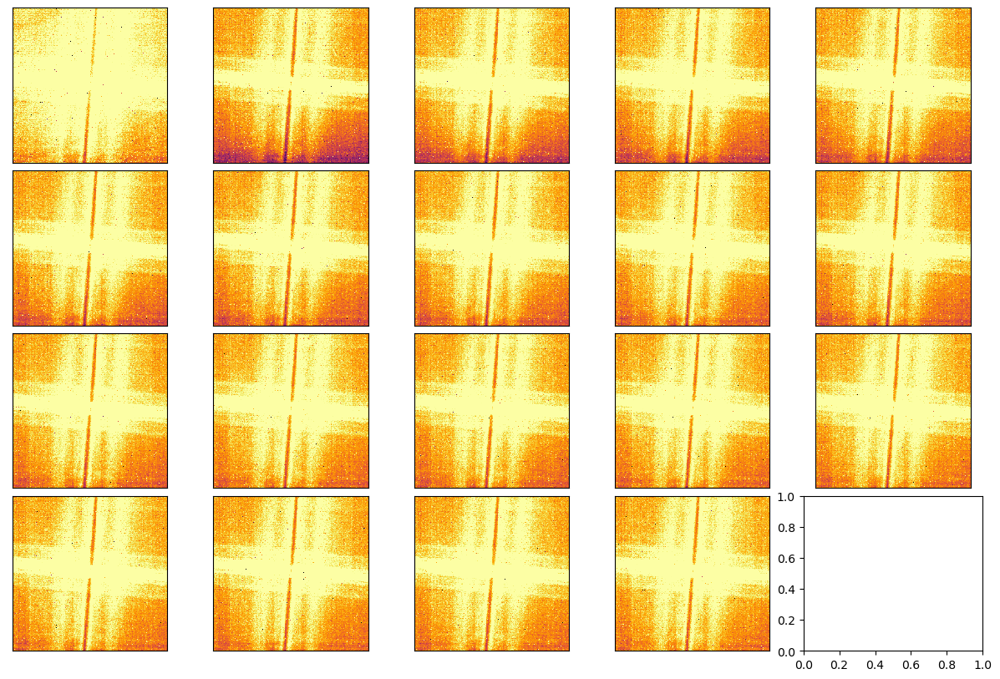

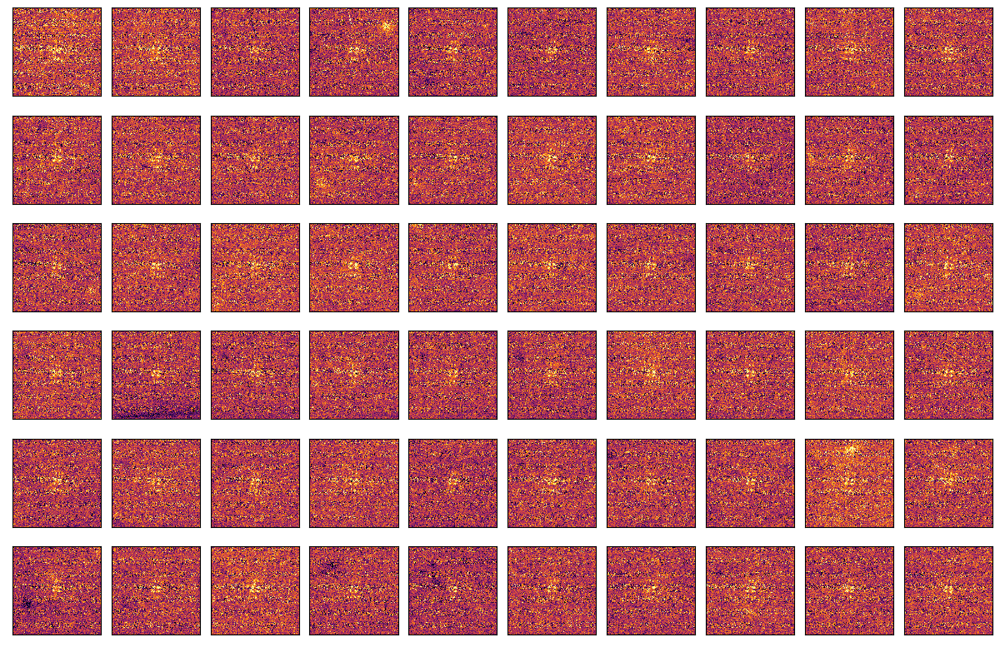

In [16]:

######################## ERS





folder="ERS_HIP_1140C/"

#comm 1045
prop="1386"

filtre="F1550C"#"F1140C"

prop="HIP65426"
rol_1=path_raw_ers+prop+"/obs5_COR_F1140C/"
rol_2=path_raw_ers+prop+"/obs4_COR_F1140C/"
ref_1=path_raw_ers+prop+"/obs6_COR_F1140C/"
bkg_1=path_raw_ers+prop+"/obs28_COR_F1140C/"
bkg_2=path_raw_ers+prop+"/obs29_COR_F1140C/"

rol_1=path_raw_ers+prop+"/obs8_COR_F1550C/"
rol_2=path_raw_ers+prop+"/obs9_COR_F1550C/"
ref_1=path_raw_ers+prop+"/obs7_COR_F1550C/"
bkg_1=path_raw_ers+prop+"/obs30_COR_F1550C/"
bkg_2=path_raw_ers+prop+"/obs31_COR_F1550C/"



img1, head1 = imp.load_cube(rol_1, "rateints", xdim=200, ydim=200, x0=120, y0=112)
img2, head2 = imp.load_cube(rol_2, "rateints", xdim=200, ydim=200, x0=120, y0=112)
img3, head3 = imp.load_cube(ref_1, "rateints", xdim=200, ydim=200, x0=120, y0=112)
tmp, head4 = imp.load_cube(bkg_1, "rateints", xdim=200, ydim=200, x0=120, y0=112)
img4 = tmp[0,:,:,:]
img5 = tmp[1,:,:,:]
tmp, head6 = imp.load_cube(bkg_2, "rateints", xdim=200, ydim=200, x0=120, y0=112)
img6 = tmp[0,:,:,:]
img7 = tmp[1,:,:,:]


deuxadeux = img1-img4

print("1: "+str(img1.shape))
print("2: "+str(img2.shape))
print("3: "+str(img3.shape))
print("4: "+str(img4.shape))
print("5: "+str(img5.shape))
print("6: "+str(img6.shape))
print("7: "+str(img7.shape))

### median of the ref dithering

img33 = np.median(img3,axis=0)

label = ["Roll 1", "Roll 2", "Ref", "Bkg Roll 1", "Bkg Roll 2", "Bkg Ref 1", "Bkg Ref 2"]
img = [img1, img2, img33, img4, img5, img6, img7]

dx=10
q1=[100+dx, -1, 0, 100-dx]
q2=[100+dx, -1, 100+dx, -1]
q3=[0, 100-dx, 0, 100-dx]
q4=[0, 100-dx,100+dx, -1]
qn=[q1,q2,q3,q4]
fcolor=['blue','orange','green','red','purple','brown','pink','grey', 'olive', 'cyan','black','yellow','indigo','darkblue']
qname = ['Quadran Upper Left','Quadran Upper Right', 'Quadran Lower Left','Quadran Lower Right']





#MEDIAN
for j in range(4):
	fig=plt.figure()
	for i in range(len(img)):
		med  = np.median(img[i][:,qn[j][0]:qn[j][1],qn[j][2]:qn[j][3]],axis=(1,2))
		mean = np.mean(img[i][:,qn[j][0]:qn[j][1],qn[j][2]:qn[j][3]],axis=(1,2))
		plt.plot(med,'D',color=fcolor[i],ms=2,mew=1.25,markerfacecolor='None')
		plt.plot(med,color=fcolor[i],label=label[i])
		medfull = np.median(img[i][:,qn[j][0]:qn[j][1],qn[j][2]:qn[j][3]])
		plt.plot([-1,100],[medfull,medfull],'--',color=fcolor[i],lw=1)
	
	plt.ylabel('ADU',fontsize=10)
	plt.xlabel('Integration number',fontsize=10)
	plt.legend(loc='upper right',fontsize='x-small')
	if filtre == 'F1140C':
		plt.ylim([5,9])
		plt.xlim([-0.5,41])
	if filtre == 'F1550C':
		plt.ylim([6.5,11])
		plt.xlim([-0.5,60])
	plt.grid()
	plt.title(qname[j]+" Median")
	fig.tight_layout()
	#fig.savefig(path_save+folder+'median_bkg_'+qname[j]+filtre+'_ERS_'+prop+'.pdf',format='pdf',bbox_inches='tight')
	#plt.close(fig)
	plt.show()

# STD DEV
for j in range(4):
	fig=plt.figure()
	for i in range(len(img)):
		stdd = np.std(img[i][:,qn[j][0]:qn[j][1],qn[j][2]:qn[j][3]],axis=(1,2))
		plt.plot(stdd,'D',color=fcolor[i],ms=2,mew=1.25,markerfacecolor='None')
		plt.plot(stdd,color=fcolor[i],label=label[i])
	
	plt.ylabel('ADU',fontsize=10)
	plt.xlabel('Integration number',fontsize=10)
	plt.legend(loc='upper right',fontsize='x-small')
	if filtre == 'F1140C':
		plt.ylim([0.5,2.5])
	if filtre == 'F1550C':
		plt.ylim([0.75,2.])	
	plt.grid()
	plt.title(qname[j]+" Std dev")
	fig.tight_layout()
	#fig.savefig(path_save+folder+'Std_dev_bkg_'+qname[j]+'F1140_ERS_'+prop+'.pdf',format='pdf',bbox_inches='tight')
	#plt.close(fig)
	plt.show()


dx=10
mask=np.zeros((200,200))+1.
mask[100-dx:100+dx,:]=0
mask[:,100-dx:100+dx]=0

vmin=0
vmax=8
fig1,[[sub1,sub2],[sub3,sub4]] = plt.subplots(nrows=2,ncols=2,figsize=(6.1,8))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
tmp1 = sub1.imshow(img1[1,100+dx:,0:100-dx],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,100-dx,100+dx,200])
tmp2 = sub2.imshow(img1[1,100+dx:,100+dx:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=[100+dx,200,100+dx,200])
tmp3 = sub3.imshow(img1[1,0:100-dx,0:100-dx],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=[0,100-dx,0,100-dx])
tmp4 = sub4.imshow(img1[1,0:100-dx,100+dx:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax,extent=[100+dx,200,0,100-dx])
sub2.get_yaxis().set_visible(False)
sub4.get_yaxis().set_visible(False)
sub1.get_xaxis().set_visible(False)
sub2.get_xaxis().set_visible(False)
cax  = fig1.add_axes([1, 0.12, 0.02, 0.75])
cbar = fig1.colorbar(tmp3, cax=cax, orientation='vertical')
cbar.set_label('ADU',fontsize=10)
cbar.ax.tick_params(length=2,pad=1,labelsize=10)
#fig1.savefig(path_save+folder+'bkg_4quadran_'+filtre+'_ERS_'+prop+'.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig1)
plt.show()


#### PLOT DES IMAGES DE BKG


# ROLL 1
vmin=0
vmax=8
fig, axs = plt.subplots(6,10, figsize=(12, 10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()
for i in range(60):
	axs[i].imshow(img1[i,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
	axs[i].get_yaxis().set_visible(False)
	axs[i].get_xaxis().set_visible(False)
#fig.savefig(path_save+folder+'roll_1_'+filtre+'_ERS_'+prop+'.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()

# ROLL 2
vmin=0
vmax=8
fig, axs = plt.subplots(6,10, figsize=(12, 10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()
for i in range(60):
	axs[i].imshow(img2[i,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
	axs[i].get_yaxis().set_visible(False)
	axs[i].get_xaxis().set_visible(False)
#fig.savefig(path_save+folder+'roll_2_'+filtre+'_ERS_'+prop+'.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()


# BKG REF 1
vmin=0
vmax=9
fig, axs = plt.subplots(4,5, figsize=(12, 10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()
for i in range(19):
	axs[i].imshow(img3[0,i,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
	axs[i].get_yaxis().set_visible(False)
	axs[i].get_xaxis().set_visible(False)
#fig.savefig(path_save+folder+'ref_1_'+filtre+'_ERS_'+prop+'.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()



# BKG ROLL 1
vmin=0
vmax=8
fig, axs = plt.subplots(6,10, figsize=(12, 10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()
for i in range(60):
	axs[i].imshow(img4[i,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
	axs[i].get_yaxis().set_visible(False)
	axs[i].get_xaxis().set_visible(False)
#fig.savefig(path_save+folder+'bkg_roll_1_'+filtre+'_ERS_'+prop+'.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()


# BKG ROLL 2
vmin=0
vmax=8
fig, axs = plt.subplots(6,10, figsize=(12, 10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()
for i in range(60):
	axs[i].imshow(img5[i,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
	axs[i].get_yaxis().set_visible(False)
	axs[i].get_xaxis().set_visible(False)
#fig.savefig(path_save+folder+'bkg_roll_2_'+filtre+'_ERS_'+prop+'.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()





# BKG REF 1
vmin=0
vmax=9
fig, axs = plt.subplots(4,5, figsize=(12, 10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()
for i in range(19):
	axs[i].imshow(img6[i,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
	axs[i].get_yaxis().set_visible(False)
	axs[i].get_xaxis().set_visible(False)
#fig.savefig(path_save+folder+'bkg_ref_1_'+filtre+'_ERS_'+prop+'.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()


# BKG REF 2
vmin=0
vmax=9
fig, axs = plt.subplots(4,5, figsize=(12, 10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()
for i in range(19):
	axs[i].imshow(img7[i,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
	axs[i].get_yaxis().set_visible(False)
	axs[i].get_xaxis().set_visible(False)
#fig.savefig(path_save+folder+'bkg_ref_2_'+filtre+'_ERS_'+prop+'.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()




# BKG ROLL 2
vmin=-1
vmax=1
fig, axs = plt.subplots(6,10, figsize=(12, 10))
plt.subplots_adjust(wspace=0.12, hspace=0.05, left=0.01, right=0.99)
axs = axs.ravel()
for i in range(60):
	axs[i].imshow(deuxadeux[i,:,:],origin='lower',cmap='inferno',interpolation='none',vmin=vmin,vmax=vmax)
	axs[i].get_yaxis().set_visible(False)
	axs[i].get_xaxis().set_visible(False)
#fig.savefig(path_save+folder+'deux_a_deux_'+filtre+'_ERS_'+prop+'.pdf',format='pdf',bbox_inches='tight')
#plt.close(fig)
plt.show()

